# Projeto A3: Mobilidade urbana em Salvador
## Notebook 2: análises exploratória (EDA), diagnóstica, preditiva e prescritiva

**UC:** Análise de Dados e Big Data (UNIFACS) · **Professor:** Eduardo Sidney da Silva Xavier

Este notebook lê as tabelas produzidas pelo ETL (`data/processed/`) e responde às perguntas do projeto:

1. **Oferta × população:** a oferta de transporte público acompanhou a população de Salvador?
2. **Por que a demanda por ônibus caiu?** (metrô, carros e motos, tarifa, pandemia, população)
3. **Mais oferta = mais congestionamento?** Ampliar a oferta de ônibus pioraria o trânsito?
4. **Para onde vai até 2030?** (projeções em cenários)
5. **O que fazer?** (recomendações para gestores)

| Tipo de análise | Pergunta-guia | Seções |
|---|---|---|
| Exploratória (EDA) | O que aconteceu? | 1 a 4 |
| Diagnóstica | Por que aconteceu? Há correlação? Há causalidade? | 5 a 7 |
| Preditiva (opcional) | Para onde vai? | 8 |
| Prescritiva (obrigatória) | O que fazer? | 9 |

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
# >>> No Google Colab: troque o endereço abaixo pelo do repositório da equipe no GitHub. <<<
REPO_GITHUB = "https://github.com/SEU-USUARIO/mobilidade-salvador-a3"
if "google.colab" in sys.modules:  # no Colab: baixa o repositório, que já traz a base tratada
    import os, subprocess
    if not Path("/content/projeto").exists():
        subprocess.run(["git", "clone", "-q", REPO_GITHUB, "/content/projeto"], check=True)
    os.chdir("/content/projeto")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import *  # noqa: E402,F401,F403  (paleta e funções de gráfico do projeto)

DADOS = RAIZ / "data" / "processed"
FIG = RAIZ / "figuras"
FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

base = pd.read_csv(DADOS / "base_salvador_anual.csv")
mensal = pd.read_csv(DADOS / "base_salvador_mensal.csv", parse_dates=["data"])
painel = pd.read_csv(DADOS / "painel_capitais_anual.csv")
pemob = pd.read_csv(DADOS / "pemob_capitais.csv")
desloc = pd.read_csv(DADOS / "deslocamento_capitais_censo.csv")
tempo_modo = pd.read_csv(DADOS / "tempo_medio_por_meio_censo2022.csv")
tarifa = pd.read_csv(DADOS / "tarifa_anual.csv")
pop_cap = pd.read_csv(DADOS / "populacao_capitais.csv")
SSA = "Salvador"
R = {}   # dicionário com os resultados-chave (vai para o dashboard e os relatórios)

---
# PARTE A. ANÁLISE EXPLORATÓRIA (EDA): o que aconteceu?
## 1. Estatística descritiva
Médias, medianas, quartis e desvio padrão das principais variáveis das 13 capitais em 2025
(e da série anual de Salvador). O **desvio padrão** e a distância entre os **quartis** mostram a dispersão.

In [2]:
vars_cap = ["populacao", "motorizacao_por_mil_hab", "autos_por_mil_hab", "motos_por_mil_hab", "onibus_reg_por_100mil_hab",
            "var_pop_desde_2014_pct", "var_motorizacao_desde_2014_pct"]
desc_cap = painel[painel["ano"] == 2025][vars_cap].describe().T
desc_cap["cv_%"] = desc_cap["std"] / desc_cap["mean"] * 100   # coeficiente de variação
desc_cap.round(2).to_csv(DADOS / "estatistica_descritiva_capitais_2025.csv")   # usada no relatório
desc_cap.round(1)

,count,mean,std,min,25%,50%,75%,max,cv_%
populacao,13.0,2941741.7,2883000.5,1041092.0,1462487.0,2129683.0,2440248.0,11479120.0,98.0
motorizacao_por_mil_hab,13.0,663.3,251.3,430.6,463.6,511.7,829.1,1176.1,37.9
autos_por_mil_hab,13.0,511.4,243.3,247.6,333.3,416.6,640.4,1026.7,47.6
motos_por_mil_hab,13.0,151.8,46.5,95.1,107.1,149.5,177.1,253.7,30.6
onibus_reg_por_100mil_hab,13.0,648.6,112.7,420.0,604.4,674.7,726.6,822.7,17.4
var_pop_desde_2014_pct,13.0,1.0,5.7,-7.1,-2.0,-0.4,1.8,13.0,568.1
var_motorizacao_desde_2014_pct,13.0,37.9,15.8,17.7,29.8,33.7,44.9,74.7,41.7


In [3]:
p25 = painel[painel["ano"] == 2025].set_index("municipio")
posicao = {v: int(p25[v].rank(ascending=False)[SSA]) for v in vars_cap}
print("Posição de Salvador entre as 13 capitais em 2025 (1 = maior valor):")
for v, pos in posicao.items():
    print(f"  {v:35s} {pos}º  (Salvador = {p25.loc[SSA, v]:,.1f}; mediana = {p25[v].median():,.1f})")
pd.DataFrame([{"variavel": v, "posicao_salvador": pos, "valor_salvador": p25.loc[SSA, v], "mediana_capitais": p25[v].median()}
              for v, pos in posicao.items()]).to_csv(DADOS / "posicao_salvador_2025.csv", index=False)

Posição de Salvador entre as 13 capitais em 2025 (1 = maior valor):
  populacao                           5º  (Salvador = 2,404,365.0; mediana = 2,129,683.0)
  motorizacao_por_mil_hab             12º  (Salvador = 437.4; mediana = 511.7)
  autos_por_mil_hab                   8º  (Salvador = 341.8; mediana = 416.6)
  motos_por_mil_hab                   11º  (Salvador = 95.7; mediana = 149.5)
  onibus_reg_por_100mil_hab           6º  (Salvador = 679.5; mediana = 674.7)
  var_pop_desde_2014_pct              13º  (Salvador = -7.1; mediana = -0.4)
  var_motorizacao_desde_2014_pct      3º  (Salvador = 46.0; mediana = 33.7)


In [4]:
desc_desloc = desloc[["pct_coletivo", "pct_onibus", "pct_automovel", "pct_moto", "pct_ativo", "tempo_medio_2022_min",
                      "pct_mais_1h_2022"]].describe().T
desc_desloc.round(2).to_csv(DADOS / "estatistica_descritiva_deslocamento_2022.csv")
desc_desloc.round(1)

,count,mean,std,min,25%,50%,75%,max
pct_coletivo,13.0,37.6,9.3,16.7,34.1,36.8,43.2,50.1
pct_onibus,13.0,33.8,7.0,16.3,32.0,35.5,37.0,44.7
pct_automovel,13.0,33.6,9.0,23.4,28.5,29.5,38.7,49.5
pct_moto,13.0,7.7,4.1,3.8,4.2,6.6,10.5,15.0
pct_ativo,13.0,16.0,3.9,10.7,13.6,15.4,16.8,24.0
tempo_medio_2022_min,13.0,39.0,6.2,30.3,35.4,37.4,42.8,50.6
pct_mais_1h_2022,13.0,17.3,6.1,9.6,14.1,15.4,21.2,29.4


## 2. Visualização inicial
### 2.1 População: o problema da série oficial e o que de fato aconteceu
A estimativa oficial do IBGE (pontilhada) dá um salto artificial em 2022 e em 2024 (mudança de base). A série
compatibilizada (linha contínua) mostra a tendência real: **Salvador perdeu população** em todo o período.

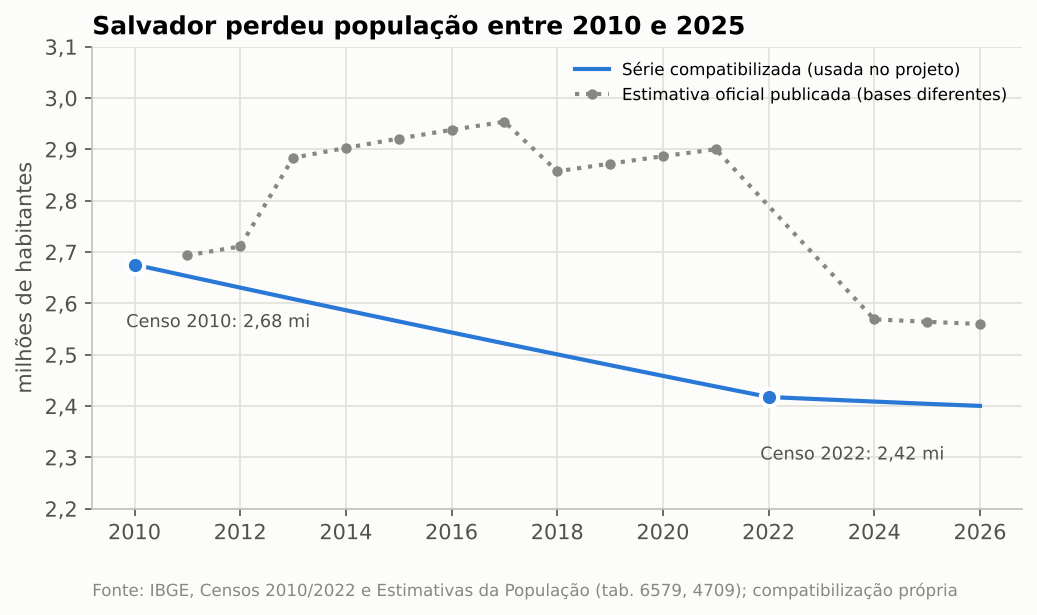

In [5]:
ssa_pop = pop_cap[pop_cap["municipio"] == SSA]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ssa_pop["ano"], ssa_pop["populacao"] / 1e6, color=DESTAQUE, label="Série compatibilizada (usada no projeto)")
of = ssa_pop.dropna(subset=["pop_estimativa_oficial"])
ax.plot(of["ano"], of["pop_estimativa_oficial"] / 1e6, color=CINZA, ls=":", marker="o", ms=4, label="Estimativa oficial publicada (bases diferentes)")
cens = ssa_pop[ssa_pop["ano"].isin([2010, 2022])]
ax.scatter(cens["ano"], cens["populacao"] / 1e6, s=70, color=DESTAQUE, zorder=3, edgecolor="white", linewidth=2)
for _, r in cens.iterrows():
    ax.annotate(f"Censo {r['ano']}: {br(r['populacao'] / 1e6, 2)} mi", (r["ano"], r["populacao"] / 1e6), textcoords="offset points",
                xytext=(-4, -30), ha="left", fontsize=8.5, color=TINTA_2)
ax.set_title("Salvador perdeu população entre 2010 e 2025")
ax.set_ylabel("milhões de habitantes")
ax.set_ylim(2.2, 3.1)
eixo_br(ax, "y", 1)
ax.legend(loc="upper right", fontsize=8)
fonte(ax, "IBGE, Censos 2010/2022 e Estimativas da População (tab. 6579, 4709); compatibilização própria")
salvar(fig, FIG / "fig01_populacao_salvador.png")
R["pop_2010"], R["pop_2022"], R["pop_2025"] = [int(ssa_pop.set_index("ano").loc[a, "populacao"]) for a in (2010, 2022, 2025)]
R["var_pop_2010_2022_pct"] = (R["pop_2022"] / R["pop_2010"] - 1) * 100

### 2.2 Pessoas × carros e motos (índice 2014 = 100)
Para comparar grandezas diferentes **sem usar dois eixos**, transformamos tudo em índice (2014 = 100).

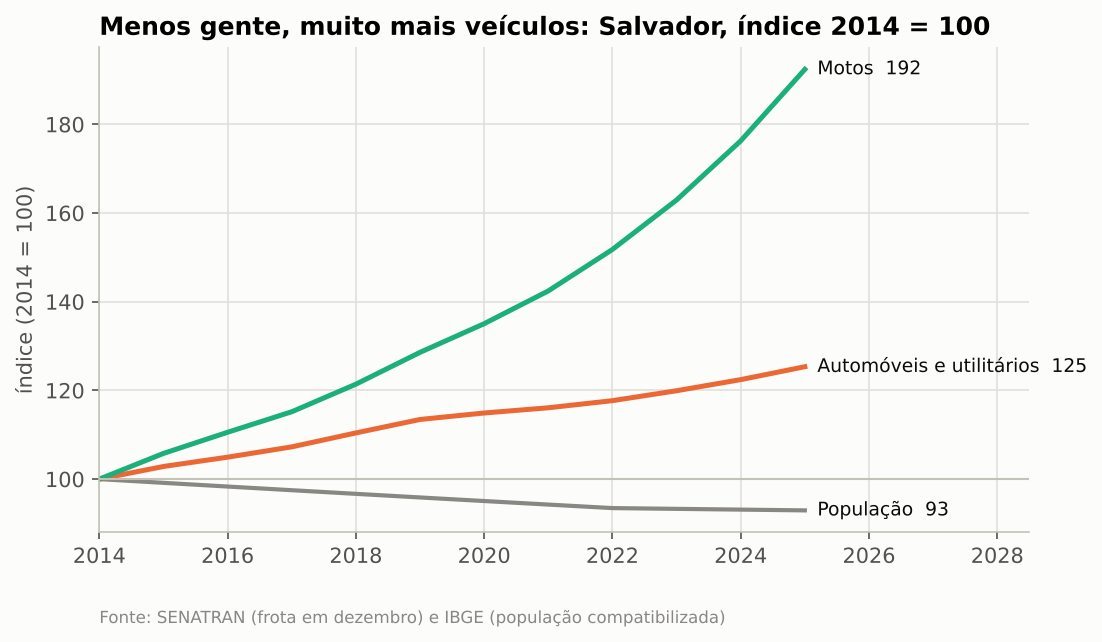

,ano,População,Automóveis e utilitários,Motos
4,2014,100.0,100.0,100.0
5,2015,99.2,102.8,105.8
6,2016,98.3,104.9,110.6
7,2017,97.5,107.3,115.2
8,2018,96.7,110.4,121.4
9,2019,95.9,113.4,128.6
10,2020,95.1,114.9,135.0
11,2021,94.3,116.1,142.4
12,2022,93.5,117.7,151.8
13,2023,93.3,119.9,162.9


In [6]:
b14 = base[base["ano"] >= 2014].copy()
idx = pd.DataFrame({"ano": b14["ano"]})
for col, nome in [("populacao", "População"), ("autos", "Automóveis e utilitários"), ("motos", "Motos")]:
    idx[nome] = b14[col].values / b14[col].iloc[0] * 100
fig, ax = plt.subplots(figsize=(8, 4.2))
cores = {"População": CINZA, "Automóveis e utilitários": LARANJA, "Motos": AQUA}
for nome, cor in cores.items():
    ax.plot(idx["ano"], idx[nome], color=cor, lw=2.4 if nome != "População" else 2)
    ax.annotate(f"{nome}  {idx[nome].iloc[-1]:.0f}", (idx["ano"].iloc[-1], idx[nome].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=TINTA)
ax.axhline(100, color=CINZA_CLARO, lw=1)
ax.set_xlim(2014, 2028.5)
ax.set_title("Menos gente, muito mais veículos: Salvador, índice 2014 = 100")
ax.set_ylabel("índice (2014 = 100)")
fonte(ax, "SENATRAN (frota em dezembro) e IBGE (população compatibilizada)")
salvar(fig, FIG / "fig02_indices_salvador.png")
R["var_autos_2014_2025_pct"] = idx["Automóveis e utilitários"].iloc[-1] - 100
R["var_motos_2014_2025_pct"] = idx["Motos"].iloc[-1] - 100
R["var_pop_2014_2025_pct"] = idx["População"].iloc[-1] - 100
R["motorizacao_2014"] = float(b14["motorizacao_por_mil_hab"].iloc[0])
R["motorizacao_2025"] = float(b14["motorizacao_por_mil_hab"].iloc[-1])
idx.round(1)

### 2.3 Metrô: crescimento, tombo na pandemia e recorde

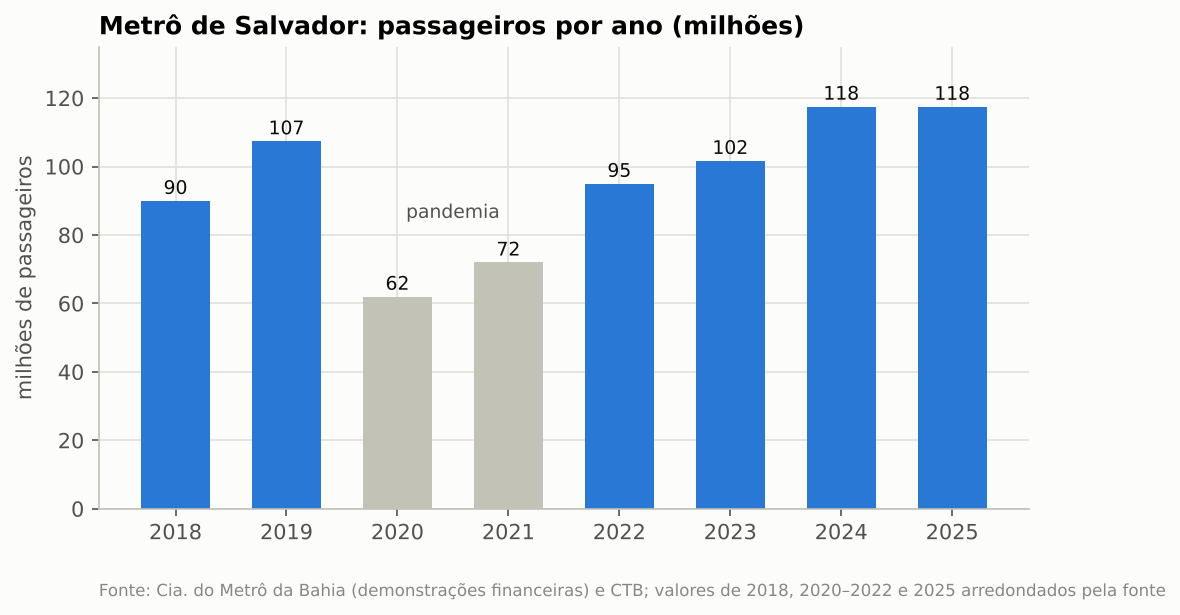

In [7]:
met = base.dropna(subset=["metro_passageiros_ano"])
fig, ax = plt.subplots(figsize=(8, 4))
cores_b = [CINZA_CLARO if a in (2020, 2021) else AZUL for a in met["ano"]]
ax.bar(met["ano"], met["metro_passageiros_ano"] / 1e6, color=cores_b, width=0.62)
for a, v in zip(met["ano"], met["metro_passageiros_ano"] / 1e6):
    ax.text(a, v + 2, f"{v:.0f}", ha="center", fontsize=9, color=TINTA)
ax.set_title("Metrô de Salvador: passageiros por ano (milhões)")
ax.set_ylabel("milhões de passageiros")
ax.set_ylim(0, 135)
ax.text(2020.5, 85, "pandemia", ha="center", color=TINTA_2, fontsize=9)
fonte(ax, "Cia. do Metrô da Bahia (demonstrações financeiras) e CTB; valores de 2018, 2020–2022 e 2025 arredondados pela fonte")
salvar(fig, FIG / "fig03_metro_anual.png")

### 2.4 Tarifa nominal × tarifa real
Mesma unidade (R$), então cabe num único eixo. A tarifa nominal mais que dobrou; a real (descontada a inflação)
variou pouco, oscilando entre R$ 5,2 e R$ 5,7 em valores de dez/2025.

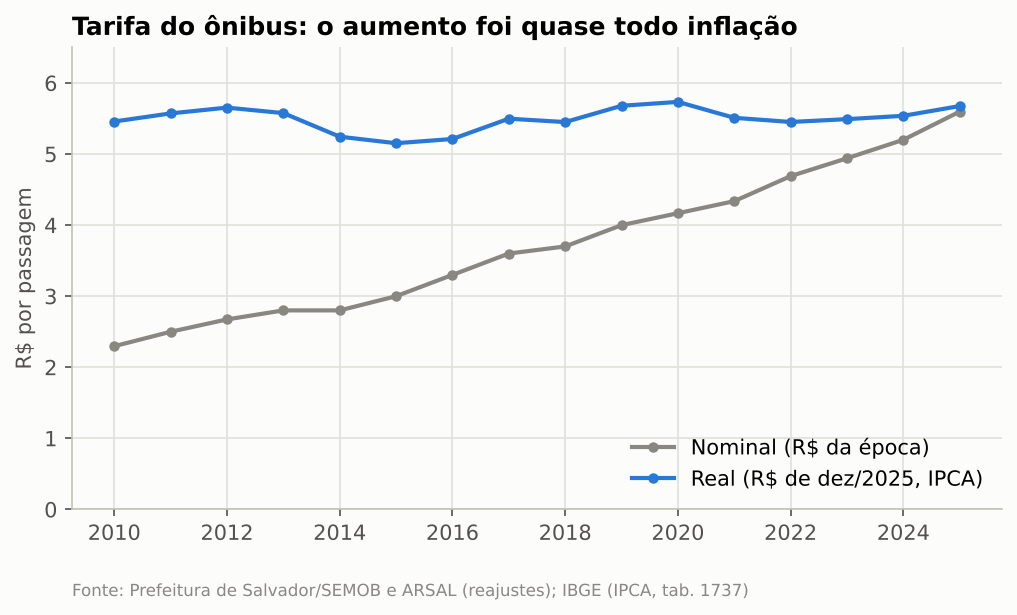

In [8]:
tf = tarifa[(tarifa["ano"] >= 2010) & (tarifa["ano"] <= 2025)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tf["ano"], tf["tarifa_media_ano"], color=CINZA, marker="o", ms=4, label="Nominal (R$ da época)")
ax.plot(tf["ano"], tf["tarifa_real_dez2025"], color=AZUL, marker="o", ms=4, label="Real (R$ de dez/2025, IPCA)")
ax.set_title("Tarifa do ônibus: o aumento foi quase todo inflação")
ax.set_ylabel("R$ por passagem")
ax.set_ylim(0, 6.5)
ax.legend(loc="lower right")
fonte(ax, "Prefeitura de Salvador/SEMOB e ARSAL (reajustes); IBGE (IPCA, tab. 1737)")
salvar(fig, FIG / "fig04_tarifa.png")
R["tarifa_real_2014"] = float(tf.set_index("ano").loc[2014, "tarifa_real_dez2025"])
R["tarifa_real_2025"] = float(tf.set_index("ano").loc[2025, "tarifa_real_dez2025"])
R["tarifa_nominal_2025"] = float(tf.set_index("ano").loc[2025, "tarifa_dezembro"])

### 2.5 Sistema de ônibus (STCO): o que dizem os números oficiais
Como só existem anos isolados (não há série aberta), usamos **pequenos múltiplos**: um painel por indicador,
cada um com sua própria fonte e definição.

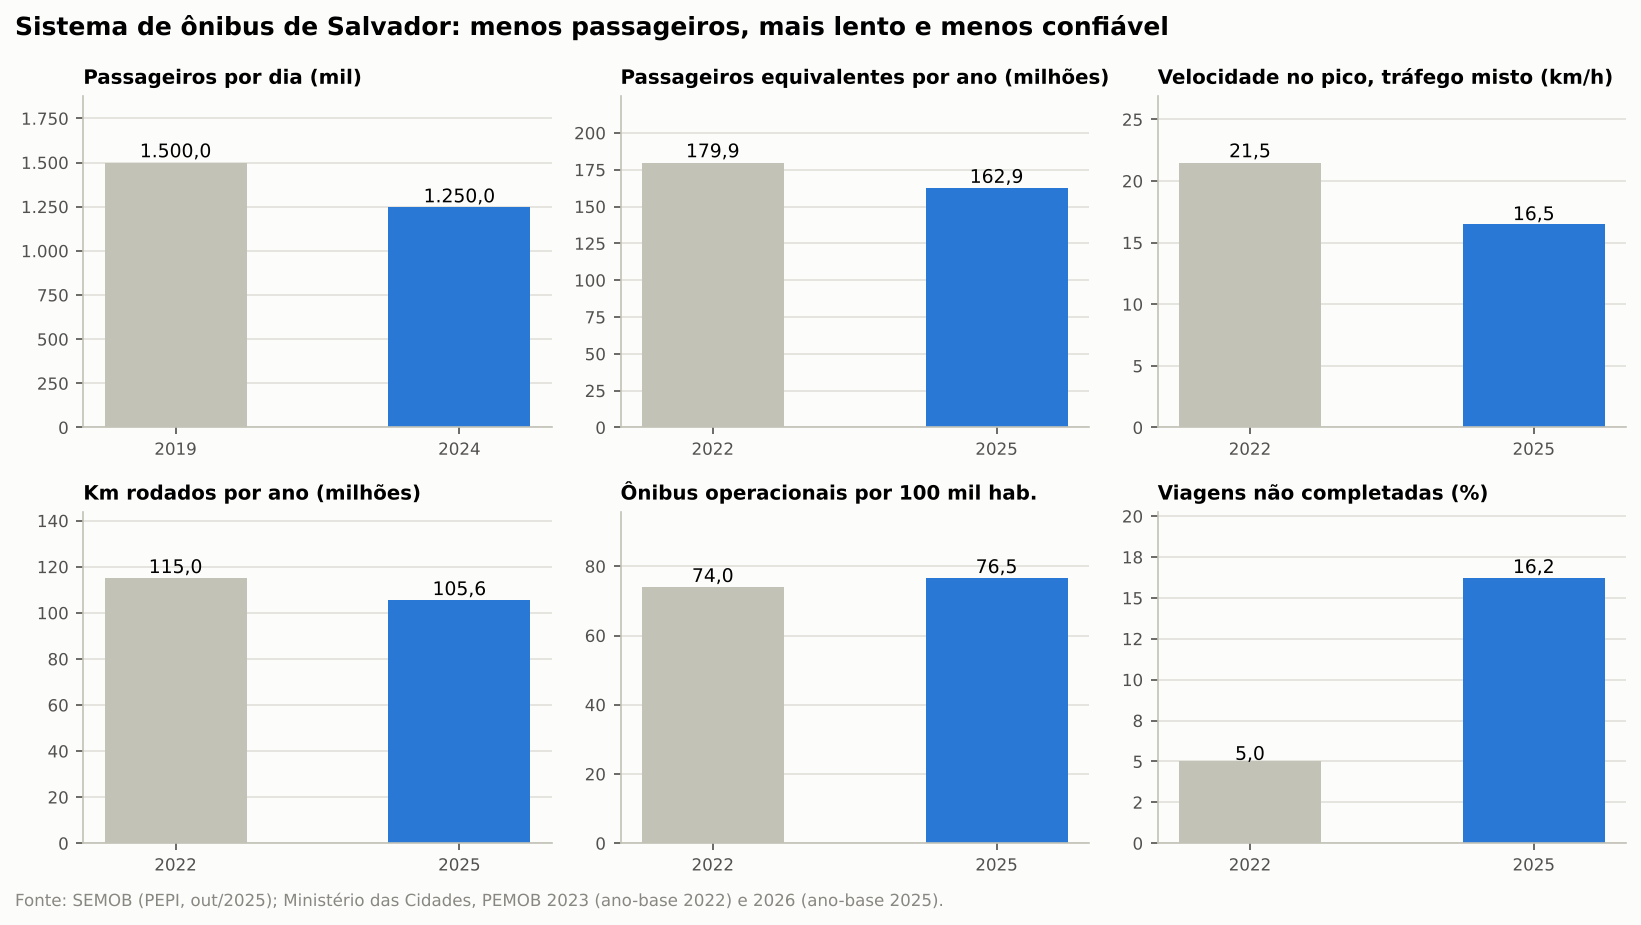

In [9]:
paineis = [
    ("Passageiros por dia (mil)", "stco_passageiros_dia_semob", 1e3, "SEMOB"),
    ("Passageiros equivalentes por ano (milhões)", "pemob_passageiros_equivalentes_onibus", 1e6, "PEMOB"),
    ("Velocidade no pico, tráfego misto (km/h)", "pemob_velocidade_trafego_misto_pico", 1, "PEMOB"),
    ("Km rodados por ano (milhões)", "pemob_km_onibus_ano", 1e6, "PEMOB"),
    ("Ônibus operacionais por 100 mil hab.", "stco_onibus_por_100mil_hab", 1, "PEMOB + IBGE"),
    ("Viagens não completadas (%)", "pemob_viagens_nao_completadas_pct", 1, "PEMOB"),
]
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, (tit, col, div, src) in zip(axes.flat, paineis):
    d = base.dropna(subset=[col])
    ax.bar(d["ano"].astype(str), d[col] / div, color=[CINZA_CLARO, AZUL][: len(d)] if len(d) == 2 else AZUL, width=0.5)
    for i, v in enumerate(d[col] / div):
        ax.text(i, v * 1.02, br(v, 1), ha="center", fontsize=9)
    ax.set_title(tit, fontsize=9.5)
    ax.set_ylim(0, (d[col] / div).max() * 1.25)
    ax.grid(axis="x", visible=False)
    ax.tick_params(labelsize=8)
    eixo_br(ax, "y", 0)
fig.suptitle("Sistema de ônibus de Salvador: menos passageiros, mais lento e menos confiável", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.text(0.01, -0.01, "Fonte: SEMOB (PEPI, out/2025); Ministério das Cidades, PEMOB 2023 (ano-base 2022) e 2026 (ano-base 2025).",
         fontsize=8, color=CINZA)
fig.tight_layout()
salvar(fig, FIG / "fig05_stco_indicadores.png")
g = base.set_index("ano")
R.update({
    "stco_pass_dia_2019": float(g.loc[2019, "stco_passageiros_dia_semob"]), "stco_pass_dia_2024": float(g.loc[2024, "stco_passageiros_dia_semob"]),
    "pass_equiv_2022": float(g.loc[2022, "pemob_passageiros_equivalentes_onibus"]), "pass_equiv_2025": float(g.loc[2025, "pemob_passageiros_equivalentes_onibus"]),
    "vel_2022": float(g.loc[2022, "pemob_velocidade_trafego_misto_pico"]), "vel_2025": float(g.loc[2025, "pemob_velocidade_trafego_misto_pico"]),
    "km_2022": float(g.loc[2022, "pemob_km_onibus_ano"]), "km_2025": float(g.loc[2025, "pemob_km_onibus_ano"]),
    "frota_op_2022": float(g.loc[2022, "pemob_frota_onibus_operacional"]), "frota_op_2025": float(g.loc[2025, "pemob_frota_onibus_operacional"]),
    "onibus_100mil_2022": float(g.loc[2022, "stco_onibus_por_100mil_hab"]), "onibus_100mil_2025": float(g.loc[2025, "stco_onibus_por_100mil_hab"]),
    "nao_completadas_2022": float(g.loc[2022, "pemob_viagens_nao_completadas_pct"]), "nao_completadas_2025": float(g.loc[2025, "pemob_viagens_nao_completadas_pct"]),
})
R["var_pass_dia_2019_2024_pct"] = (R["stco_pass_dia_2024"] / R["stco_pass_dia_2019"] - 1) * 100
R["var_vel_pct"] = (R["vel_2025"] / R["vel_2022"] - 1) * 100

### 2.6 Série mensal: ônibus × metrô (2024–2025, índice média de 2024 = 100)

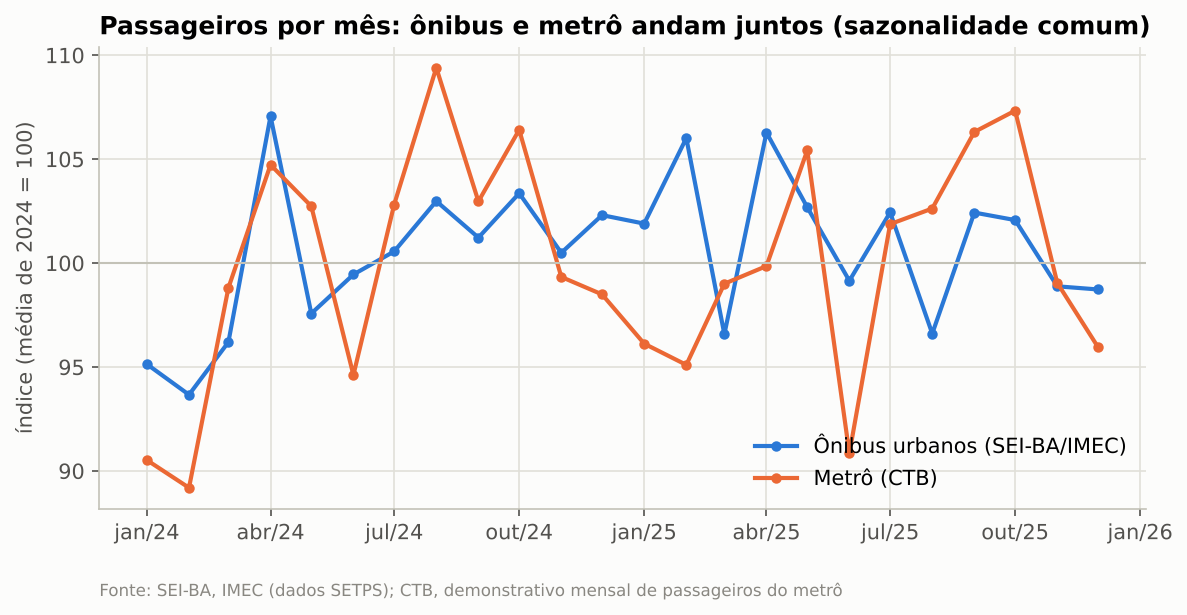

In [10]:
m = mensal[mensal["ano"] >= 2024]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(m["data"], m["indice_onibus_2024_100"], color=AZUL, marker="o", ms=4, label="Ônibus urbanos (SEI-BA/IMEC)")
ax.plot(m["data"], m["indice_metro_2024_100"], color=LARANJA, marker="o", ms=4, label="Metrô (CTB)")
ax.axhline(100, color=CINZA_CLARO, lw=1)
ax.set_title("Passageiros por mês: ônibus e metrô andam juntos (sazonalidade comum)")
eixo_mes(ax)
ax.yaxis.set_major_locator(plt.MultipleLocator(5))
eixo_br(ax, "y", 0)
ax.set_ylabel("índice (média de 2024 = 100)")
ax.legend(loc="lower right")
fonte(ax, "SEI-BA, IMEC (dados SETPS); CTB, demonstrativo mensal de passageiros do metrô")
salvar(fig, FIG / "fig06_mensal_onibus_metro.png")

### 2.7 Distribuições e anomalias (histograma e boxplot)
* **Boxplot** da motorização das 13 capitais ano a ano: a caixa mostra os quartis; Salvador é o ponto azul.
* **Histograma** do índice mensal de ônibus: concentração entre 100 e 110, com meses fora da curva.

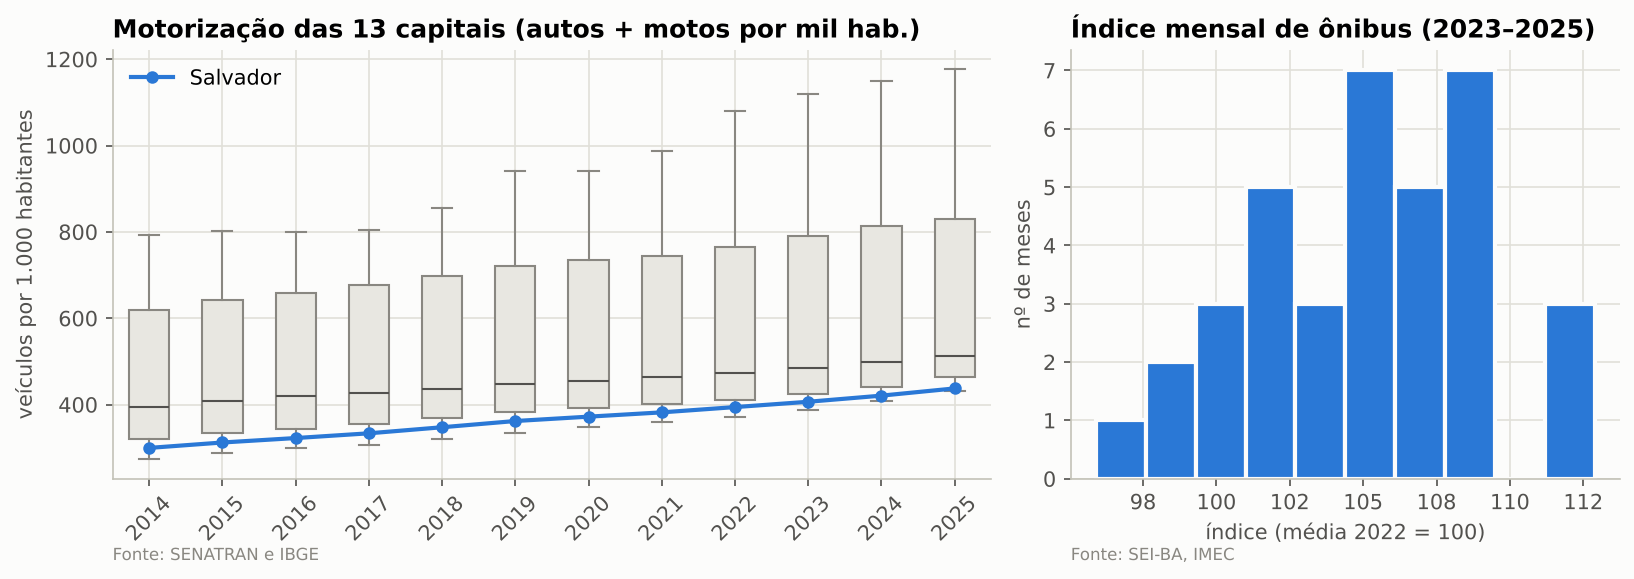

,municipio,motorizacao_por_mil_hab
11,Belo Horizonte,1176.0
47,Curitiba,1046.0


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
dados_box = [painel[painel["ano"] == a]["motorizacao_por_mil_hab"].values for a in range(2014, 2026)]
ax.boxplot(dados_box, positions=range(2014, 2026), widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#e8e7e1", color=CINZA), medianprops=dict(color=TINTA_2), whiskerprops=dict(color=CINZA),
           capprops=dict(color=CINZA), flierprops=dict(marker="o", markerfacecolor=CINZA, markeredgecolor="white", ms=6))
s = painel[painel["municipio"] == SSA]
ax.plot(s["ano"], s["motorizacao_por_mil_hab"], color=DESTAQUE, marker="o", ms=5, label="Salvador")
ax.set_title("Motorização das 13 capitais (autos + motos por mil hab.)")
ax.set_ylabel("veículos por 1.000 habitantes")
ax.tick_params(axis="x", labelrotation=45)
ax.legend(loc="upper left")
fonte(ax, "SENATRAN e IBGE")
ax = axes[1]
ax.hist(mensal["indice_onibus_urbanos"], bins=10, color=AZUL, edgecolor=SUPERFICIE, linewidth=2)
ax.set_title("Índice mensal de ônibus (2023–2025)")
ax.set_xlabel("índice (média 2022 = 100)")
eixo_br(ax, "x", 0)
ax.set_ylabel("nº de meses")
fonte(ax, "SEI-BA, IMEC")
fig.tight_layout()
salvar(fig, FIG / "fig07_distribuicoes.png")
outliers = painel[(painel["ano"] == 2025)].nlargest(2, "motorizacao_por_mil_hab")[["municipio", "motorizacao_por_mil_hab"]]
outliers.round(0)

**Anomalias identificadas:**
* **Belo Horizonte e Curitiba** têm motorização muito acima das demais (> 1.000 veículos por mil hab.). Uma explicação
  possível é o registro de frotas de empresas, como locadoras, na cidade-sede (hipótese não verificada com dados oficiais).
  Mantivemos os dados (são oficiais), mas a comparação entre capitais usa também a **mediana**, que é robusta a esses extremos.
* **2020–2021:** queda abrupta no metrô (pandemia), tratada com a variável `pandemia` nas análises.
* **PEMOB:** algumas capitais declararam valores incoerentes (ex.: Belém com 675 milhões de km rodados por ano,
  quase 6 vezes o de Salvador, com um terço da frota). Por isso, da PEMOB das outras capitais usamos só frota e velocidade.

## 3. Padrões: tendência e sazonalidade
### 3.1 Tendência (regressão linear no tempo)

In [12]:
def tendencia(x, y):
    res = stats.linregress(x, y)
    return res.slope, res.rvalue ** 2, res.pvalue


tendencias = []
for col, nome in [("populacao", "População"), ("motorizacao_por_mil_hab", "Motorização (por mil hab.)"),
                  ("autos", "Autos"), ("motos", "Motos")]:
    sl, r2, p = tendencia(b14["ano"], b14[col])
    tendencias.append({"serie": nome, "inclinacao_por_ano": sl, "r2": r2, "p_valor": p})
    print(f"{nome:28s} inclinação = {sl:+,.1f} por ano | R² = {r2:.3f} | p-valor = {p:.2g}")
pd.DataFrame(tendencias).to_csv(DADOS / "tendencias_lineares_2014_2025.csv", index=False)
sl, r2, _ = tendencia(b14["ano"], b14["motorizacao_por_mil_hab"])
R["motorizacao_slope"], R["motorizacao_r2"] = sl, r2

População                    inclinação = -17,668.5 por ano | R² = 0.968 | p-valor = 8.4e-09
Motorização (por mil hab.)   inclinação = +12.2 por ano | R² = 0.998 | p-valor = 9.7e-15
Autos                        inclinação = +14,451.6 por ano | R² = 0.991 | p-valor = 1.3e-11
Motos                        inclinação = +9,490.4 por ano | R² = 0.962 | p-valor = 2.1e-08


### 3.2 Sazonalidade mensal
Média de cada mês (2023–2025 para ônibus; 2024–2026 para metrô) dividida pela média geral.

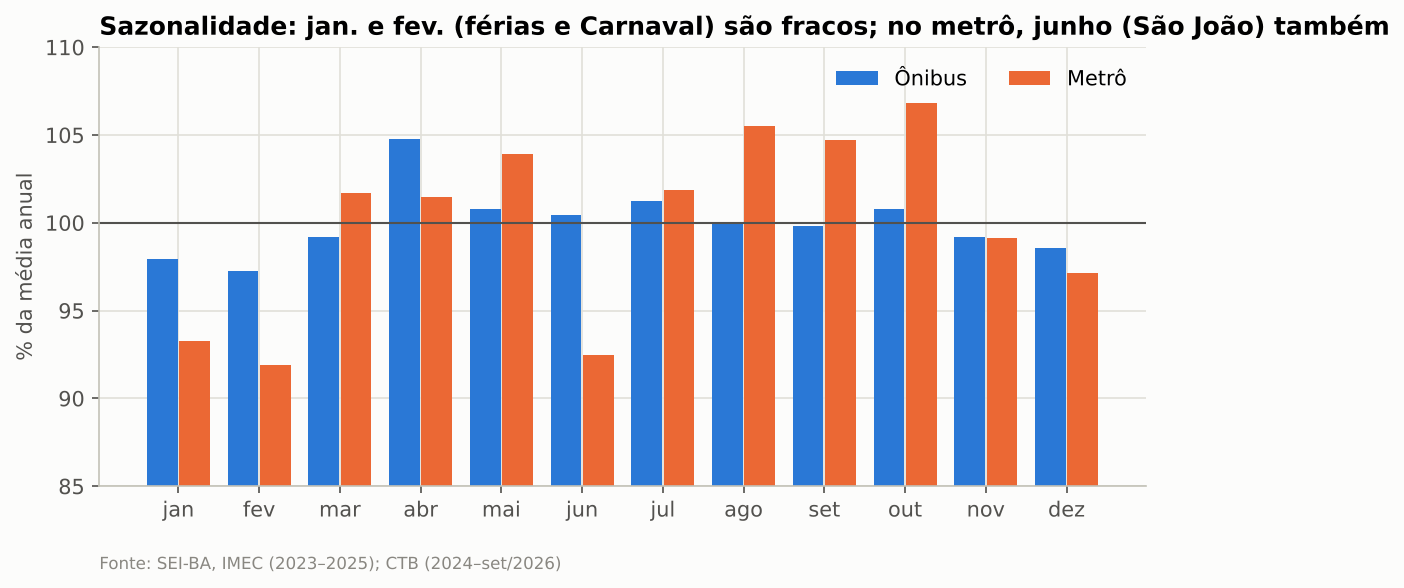

Correlação mensal ônibus × metrô (2024–2025, n = 24): r = 0.50, p = 0.013


,onibus_%media,metro_%media
jan,97.9,93.3
fev,97.2,91.9
mar,99.2,101.7
abr,104.8,101.5
mai,100.8,103.9
jun,100.4,92.5
jul,101.2,101.9
ago,100.0,105.5
set,99.8,104.7
out,100.8,106.8


In [13]:
saz_on = mensal.groupby("mes")["indice_onibus_urbanos"].mean()
saz_on = saz_on / saz_on.mean() * 100
metro_m = pd.read_csv(DADOS / "metro_mensal.csv")
saz_me = metro_m.groupby("mes")["passageiros"].mean()
saz_me = saz_me / saz_me.mean() * 100
meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(12)
ax.bar(x - 0.2, saz_on.values, width=0.38, color=AZUL, label="Ônibus")
ax.bar(x + 0.2, saz_me.values, width=0.38, color=LARANJA, label="Metrô")
ax.axhline(100, color=TINTA_2, lw=1)
ax.set_xticks(x, meses)
ax.set_ylim(85, 110)
ax.set_title("Sazonalidade: jan. e fev. (férias e Carnaval) são fracos; no metrô, junho (São João) também")
ax.set_ylabel("% da média anual")
ax.legend(loc="upper right", ncol=2)
fonte(ax, "SEI-BA, IMEC (2023–2025); CTB (2024–set/2026)")
salvar(fig, FIG / "fig08_sazonalidade.png")
r_mensal, p_mensal = stats.pearsonr(m["indice_onibus_2024_100"], m["indice_metro_2024_100"])
R["corr_mensal_onibus_metro"], R["p_mensal_onibus_metro"] = r_mensal, p_mensal
print(f"Correlação mensal ônibus × metrô (2024–2025, n = {len(m)}): r = {r_mensal:.2f}, p = {p_mensal:.3f}")
pd.DataFrame({"onibus_%media": saz_on.round(1).values, "metro_%media": saz_me.round(1).values}, index=meses)

### 3.3 Comparação entre capitais: quem usa mais transporte coletivo?

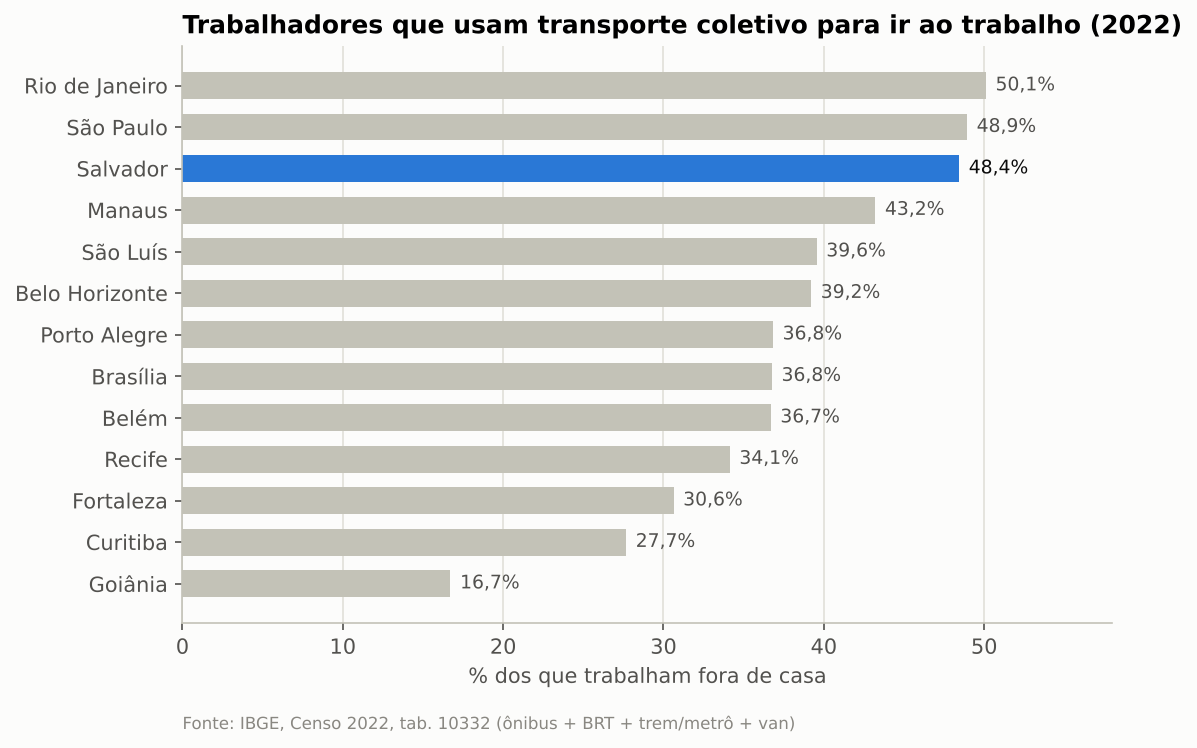

In [14]:
d = desloc.sort_values("pct_coletivo")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(d["municipio"], d["pct_coletivo"], color=[DESTAQUE if mu == SSA else CINZA_CLARO for mu in d["municipio"]], height=0.65)
for i, (v, mu) in enumerate(zip(d["pct_coletivo"], d["municipio"])):
    ax.text(v + 0.6, i, f"{v:.1f}%".replace(".", ","), va="center", fontsize=9, color=TINTA if mu == SSA else TINTA_2)
ax.set_title("Trabalhadores que usam transporte coletivo para ir ao trabalho (2022)")
ax.set_xlabel("% dos que trabalham fora de casa")
ax.set_xlim(0, 58)
ax.grid(axis="y", visible=False)
fonte(ax, "IBGE, Censo 2022, tab. 10332 (ônibus + BRT + trem/metrô + van)")
salvar(fig, FIG / "fig09_coletivo_capitais.png")
dssa = desloc.set_index("municipio").loc[SSA]
R.update({"pct_onibus_ssa": dssa["pct_onibus"], "pct_coletivo_ssa": dssa["pct_coletivo"], "pct_auto_ssa": dssa["pct_automovel"],
          "pct_ativo_ssa": dssa["pct_ativo"], "tempo_medio_ssa": dssa["tempo_medio_2022_min"],
          "rank_onibus_ssa": int(desloc["pct_onibus"].rank(ascending=False)[desloc["municipio"] == SSA].iloc[0])})

### 3.4 Quanto tempo cada meio de transporte leva (Salvador, 2022)
Tempo médio estimado pelo ponto médio das faixas de tempo do Censo (aproximação).

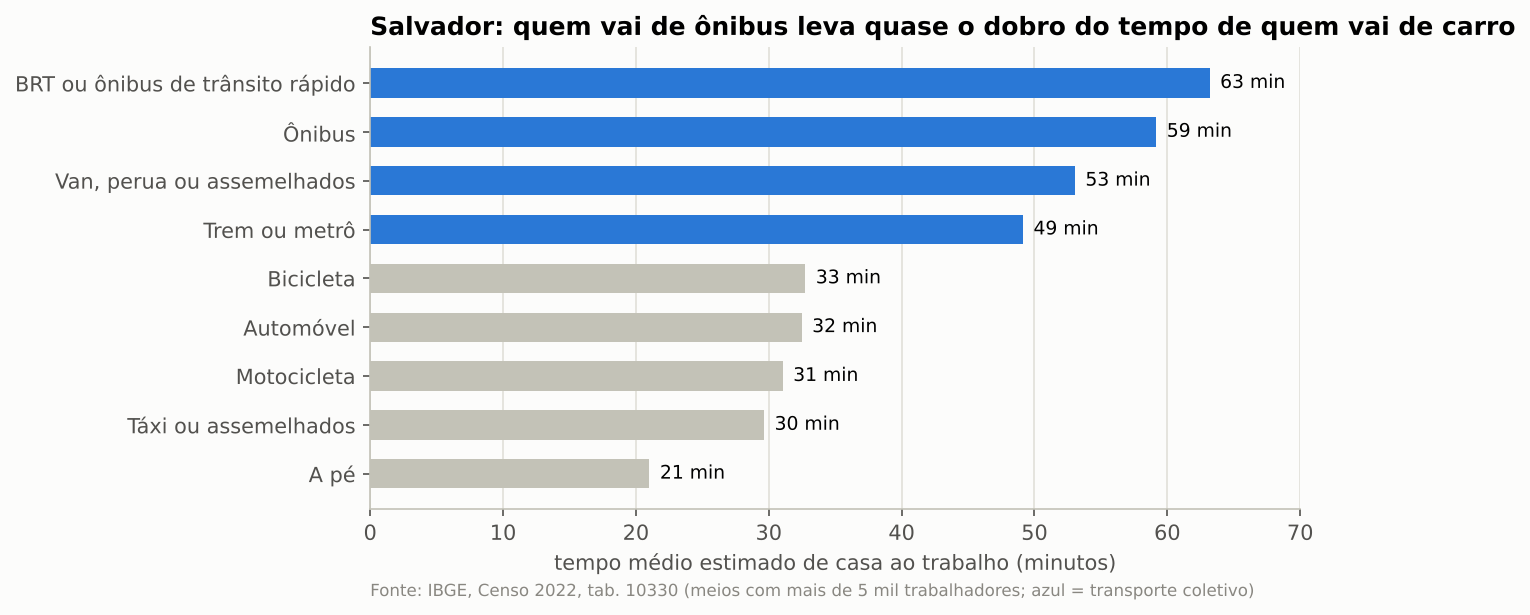

,meio_transporte,trabalhadores,tempo_medio_min
70,A pé,123804.0,21.0
81,Táxi ou assemelhados,9313.0,29.6
77,Motocicleta,30072.0,31.0
71,Automóvel,212342.0,32.5
73,Bicicleta,10321.0,32.7
80,Trem ou metrô,18131.0,49.1
82,"Van, perua ou assemelhados",6687.0,53.0
83,Ônibus,364185.0,59.2
72,BRT ou ônibus de trânsito rápido,6016.0,63.2


In [15]:
t = tempo_modo[(tempo_modo["municipio"] == SSA) & (tempo_modo["trabalhadores"] > 5000)].sort_values("tempo_medio_min")
fig, ax = plt.subplots(figsize=(8, 4))
cor_t = [AZUL if mt in ("Ônibus", "Trem ou metrô", "Van, perua ou assemelhados", "BRT ou ônibus de trânsito rápido") else CINZA_CLARO
         for mt in t["meio_transporte"]]
ax.barh(t["meio_transporte"], t["tempo_medio_min"], color=cor_t, height=0.6)
for i, v in enumerate(t["tempo_medio_min"]):
    ax.text(v + 0.8, i, f"{v:.0f} min", va="center", fontsize=9)
ax.set_title("Salvador: quem vai de ônibus leva quase o dobro do tempo de quem vai de carro")
ax.set_xlabel("tempo médio estimado de casa ao trabalho (minutos)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 70)
fonte(ax, "IBGE, Censo 2022, tab. 10330 (meios com mais de 5 mil trabalhadores; azul = transporte coletivo)")
salvar(fig, FIG / "fig10_tempo_por_meio.png")
tm = t.set_index("meio_transporte")["tempo_medio_min"]
R["tempo_onibus_min"], R["tempo_auto_min"] = float(tm["Ônibus"]), float(tm["Automóvel"])
t[["meio_transporte", "trabalhadores", "tempo_medio_min"]].round(1)

### 3.5 Tempo de deslocamento: 2010 × 2022

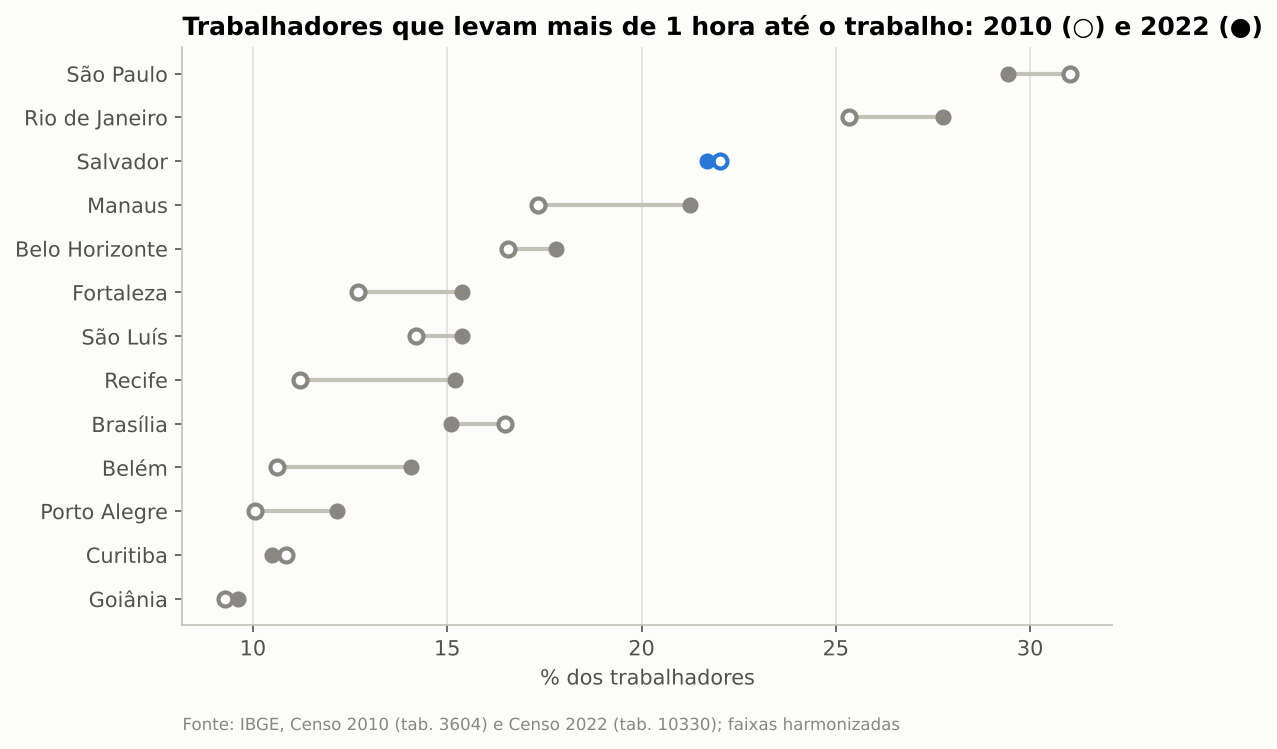

In [16]:
dd = desloc.sort_values("pct_mais_1h_2022")
fig, ax = plt.subplots(figsize=(8, 5))
for i, r in enumerate(dd.itertuples()):
    cor = DESTAQUE if r.municipio == SSA else CINZA
    ax.plot([r.pct_mais_1h_2010, r.pct_mais_1h_2022], [i, i], color=CINZA_CLARO, lw=2, zorder=1)
    ax.scatter(r.pct_mais_1h_2010, i, color="white", edgecolor=cor, s=45, zorder=2, linewidth=2)
    ax.scatter(r.pct_mais_1h_2022, i, color=cor, s=45, zorder=3)
ax.set_yticks(range(len(dd)), dd["municipio"])
ax.set_title("Trabalhadores que levam mais de 1 hora até o trabalho: 2010 (○) e 2022 (●)")
ax.set_xlabel("% dos trabalhadores")
ax.grid(axis="y", visible=False)
fonte(ax, "IBGE, Censo 2010 (tab. 3604) e Censo 2022 (tab. 10330); faixas harmonizadas")
salvar(fig, FIG / "fig11_tempo_2010_2022.png")
R["mais1h_2010"], R["mais1h_2022"] = float(dssa["pct_mais_1h_2010"]), float(dssa["pct_mais_1h_2022"])

## 4. Agrupamentos naturais entre as capitais (k-means)
O **k-means** reúne capitais parecidas em grupos. Usamos 3 variáveis padronizadas (média 0, desvio 1, para que
nenhuma "pese" mais por causa da escala): % de trabalhadores em transporte coletivo (2022), motorização (2022) e
tempo médio de deslocamento (2022). O número de grupos (k = 3) foi escolhido pelo método do cotovelo (inércia).

Inércia por k (método do cotovelo): {1: 39.0, 2: 20.8, 3: 11.5, 4: 7.0, 5: 4.4, 6: 2.8}


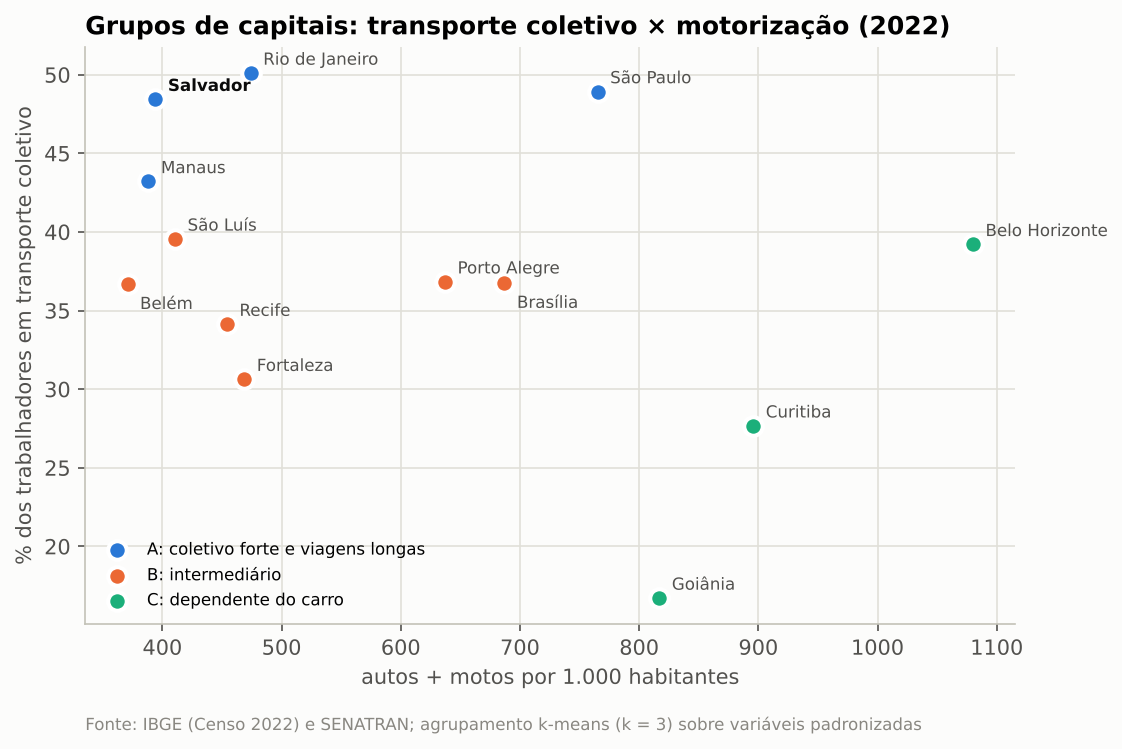

,grupo_nome,municipio,pct_coletivo,motorizacao_por_mil_hab,tempo_medio_2022_min
0,A: coletivo forte e viagens longas,Salvador,48.4,394.2,43.8
1,A: coletivo forte e viagens longas,São Paulo,48.9,765.2,50.6
2,A: coletivo forte e viagens longas,Rio de Janeiro,50.1,474.1,49.8
6,A: coletivo forte e viagens longas,Manaus,43.2,388.3,42.8
3,B: intermediário,Brasília,36.8,687.0,37.4
4,B: intermediário,Fortaleza,30.6,468.8,36.6
8,B: intermediário,Recife,34.1,454.2,37.4
10,B: intermediário,Belém,36.7,370.8,35.4
11,B: intermediário,Porto Alegre,36.8,637.2,34.3
12,B: intermediário,São Luís,39.6,410.7,36.9


In [17]:
p22 = painel[painel["ano"] == 2022][["municipio", "motorizacao_por_mil_hab", "densidade_2022"]]
clu = desloc[["municipio", "pct_coletivo", "tempo_medio_2022_min"]].merge(p22)
X = StandardScaler().fit_transform(clu[["pct_coletivo", "motorizacao_por_mil_hab", "tempo_medio_2022_min"]])
inercia = {k: KMeans(n_clusters=k, n_init=20, random_state=42).fit(X).inertia_ for k in range(1, 7)}
print("Inércia por k (método do cotovelo):", {k: round(v, 1) for k, v in inercia.items()})
km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X)
clu["grupo"] = km.labels_
ordem = clu.groupby("grupo")["pct_coletivo"].mean().sort_values(ascending=False).index
nomes_g = dict(zip(ordem, ["A: coletivo forte e viagens longas", "B: intermediário", "C: dependente do carro"]))
clu["grupo_nome"] = clu["grupo"].map(nomes_g)
fig, ax = plt.subplots(figsize=(8, 5))
for (gnome, gdf), cor in zip(clu.groupby("grupo_nome"), [AZUL, LARANJA, AQUA]):
    ax.scatter(gdf["motorizacao_por_mil_hab"], gdf["pct_coletivo"], s=80, color=cor, label=gnome, edgecolor="white", linewidth=2, zorder=3)
    for r in gdf.itertuples():
        desloc_y = -12 if r.municipio in ("Brasília", "Belém") else 4
        ax.annotate(r.municipio, (r.motorizacao_por_mil_hab, r.pct_coletivo), xytext=(6, desloc_y), textcoords="offset points",
                    fontsize=8, color=TINTA if r.municipio == SSA else TINTA_2, fontweight="bold" if r.municipio == SSA else "normal")
ax.set_title("Grupos de capitais: transporte coletivo × motorização (2022)")
ax.set_xlabel("autos + motos por 1.000 habitantes")
ax.set_ylabel("% dos trabalhadores em transporte coletivo")
ax.legend(loc="lower left", fontsize=8)
fonte(ax, "IBGE (Censo 2022) e SENATRAN; agrupamento k-means (k = 3) sobre variáveis padronizadas")
salvar(fig, FIG / "fig12_grupos_capitais.png")
R["grupo_ssa"] = clu.set_index("municipio").loc[SSA, "grupo_nome"]
clu.sort_values("grupo_nome")[["grupo_nome", "municipio", "pct_coletivo", "motorizacao_por_mil_hab", "tempo_medio_2022_min"]].round(1)

---
# PARTE B. ANÁLISE DIAGNÓSTICA: por que aconteceu?
## 5. Correlações
### 5.1 Entre capitais (corte transversal, 2022, n = 13)
Calculamos **Pearson** (relação linear) e **Spearman** (relação de ordem, menos sensível a extremos como BH).
Com n = 13, só correlações fortes são estatisticamente significativas (p < 0,05).

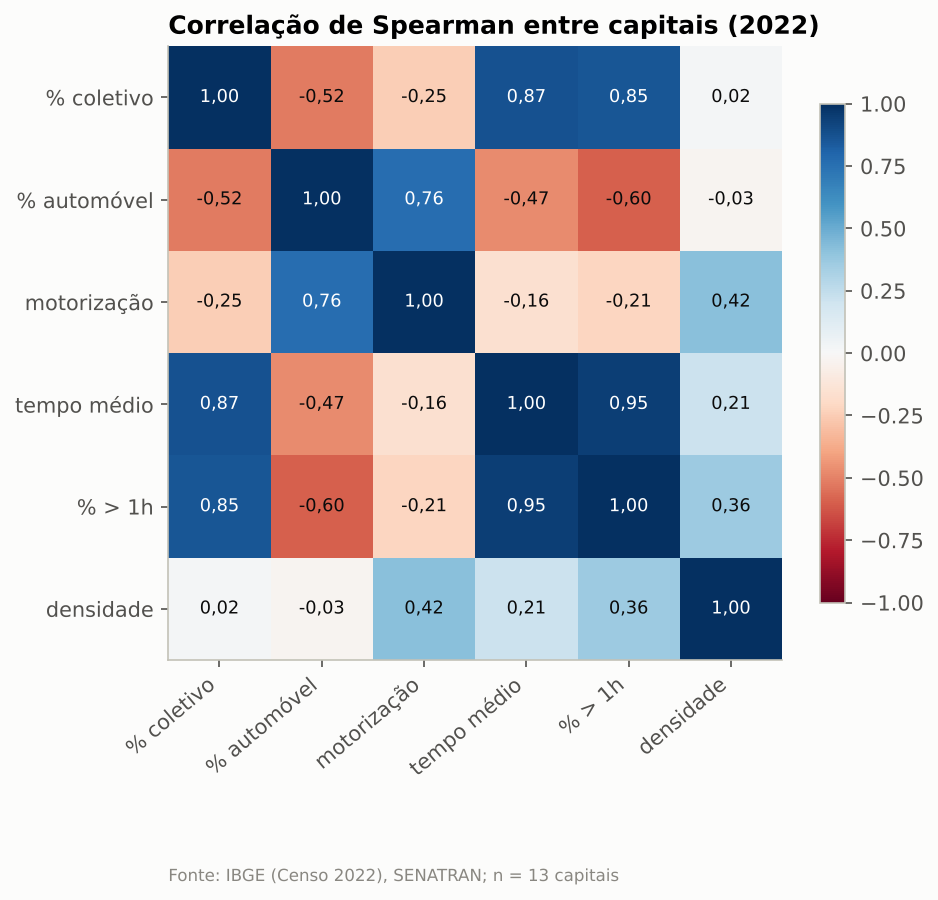

,par,pearson_r,p_pearson,spearman_rho,p_spearman
0,pct_coletivo × motorizacao_por_mil_hab,-0.338,0.258,-0.247,0.415
1,pct_coletivo × tempo_medio_2022_min,0.892,0.000,0.874,0.000
2,pct_automovel × motorizacao_por_mil_hab,0.679,0.011,0.764,0.002
3,pct_coletivo × densidade_2022,0.131,0.669,0.022,0.943


In [18]:
cross = clu.merge(desloc[["municipio", "pct_automovel", "pct_mais_1h_2022"]])
variaveis = ["pct_coletivo", "pct_automovel", "motorizacao_por_mil_hab", "tempo_medio_2022_min", "pct_mais_1h_2022", "densidade_2022"]
rotulos = ["% coletivo", "% automóvel", "motorização", "tempo médio", "% > 1h", "densidade"]
corr_s = cross[variaveis].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(corr_s.values, cmap="RdBu", vmin=-1, vmax=1)  # divergente azul-vermelho, neutro no zero
ax.set_xticks(range(len(rotulos)), rotulos, rotation=40, ha="right")
ax.set_yticks(range(len(rotulos)), rotulos)
ax.grid(False)
for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        v = corr_s.values[i, j]
        ax.text(j, i, f"{v:.2f}".replace(".", ","), ha="center", va="center", fontsize=8.5, color="white" if abs(v) > 0.6 else TINTA)
ax.set_title("Correlação de Spearman entre capitais (2022)")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.annotate("Fonte: IBGE (Censo 2022), SENATRAN; n = 13 capitais", xy=(0, -0.36), xycoords="axes fraction", fontsize=8, color=CINZA)
salvar(fig, FIG / "fig13_correlacao_capitais.png")

pares = [("pct_coletivo", "motorizacao_por_mil_hab"), ("pct_coletivo", "tempo_medio_2022_min"),
         ("pct_automovel", "motorizacao_por_mil_hab"), ("pct_coletivo", "densidade_2022")]
linhas = []
for a, b_ in pares:
    rp, pp = stats.pearsonr(cross[a], cross[b_])
    rs, ps = stats.spearmanr(cross[a], cross[b_])
    linhas.append({"par": f"{a} × {b_}", "pearson_r": rp, "p_pearson": pp, "spearman_rho": rs, "p_spearman": ps})
tab_corr = pd.DataFrame(linhas)
R["rho_coletivo_tempo"] = float(tab_corr.loc[1, "spearman_rho"])
R["p_coletivo_tempo"] = float(tab_corr.loc[1, "p_spearman"])
R["rho_coletivo_motoriz"] = float(tab_corr.loc[0, "spearman_rho"])
R["p_coletivo_motoriz"] = float(tab_corr.loc[0, "p_spearman"])
tab_corr.to_csv(DADOS / "correlacoes_capitais_2022.csv", index=False)
tab_corr.round(3)

### 5.2 Ao longo do tempo em Salvador (2014–2025, n = 12)
**Atenção, correlação espúria:** duas séries com tendência (uma subindo, outra descendo) ficam fortemente
correlacionadas mesmo sem relação de causa. Por isso também calculamos a correlação das **variações anuais**
(primeiras diferenças), que remove a tendência comum.

In [19]:
st = base[(base["ano"] >= 2014)][["ano", "populacao", "motorizacao_por_mil_hab", "tarifa_real_dez2025"]].copy()
r_niv, p_niv = stats.pearsonr(st["populacao"], st["motorizacao_por_mil_hab"])
dif = st.diff().dropna()
r_dif, p_dif = stats.pearsonr(dif["populacao"], dif["motorizacao_por_mil_hab"])
print(f"População × motorização, nível:     r = {r_niv:+.2f} (p = {p_niv:.2g})")
print(f"População × motorização, variações: r = {r_dif:+.2f} (p = {p_dif:.2g})")
R["r_pop_motoriz_nivel"], R["r_pop_motoriz_dif"], R["p_pop_motoriz_dif"] = r_niv, r_dif, p_dif

População × motorização, nível:     r = -0.98 (p = 4.7e-08)
População × motorização, variações: r = +0.56 (p = 0.073)


A correlação em nível é quase −1, mas a das variações anuais muda de sinal (+0,56) e não é significativa a 5%
(p = 0,07): **não é a queda da
população que "causa" a motorização**; as duas seguem tendências próprias (envelhecimento/saída de moradores de um lado;
renda, crédito, aplicativos e entregas de moto do outro). É um exemplo didático de por que correlação não é causalidade.

## 6. Regressão linear
### 6.1 Entre capitais: o uso do coletivo explica o tempo de viagem?
Modelo: `tempo_medio = β0 + β1·%coletivo + β2·densidade + erro` (MQO / OLS). Os coeficientes dizem quantos minutos a
mais, em média, cada ponto percentual de uso do coletivo está associado, mantida a densidade constante.

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const             15.4490      3.279      4.712      0.001       8.143      22.755
pct_coletivo       0.5752      0.084      6.873      0.000       0.389       0.762
densidade_2022     0.0005      0.000      1.780      0.105      -0.000       0.001
R² = 0.845 | R² ajustado = 0.814 | n = 13


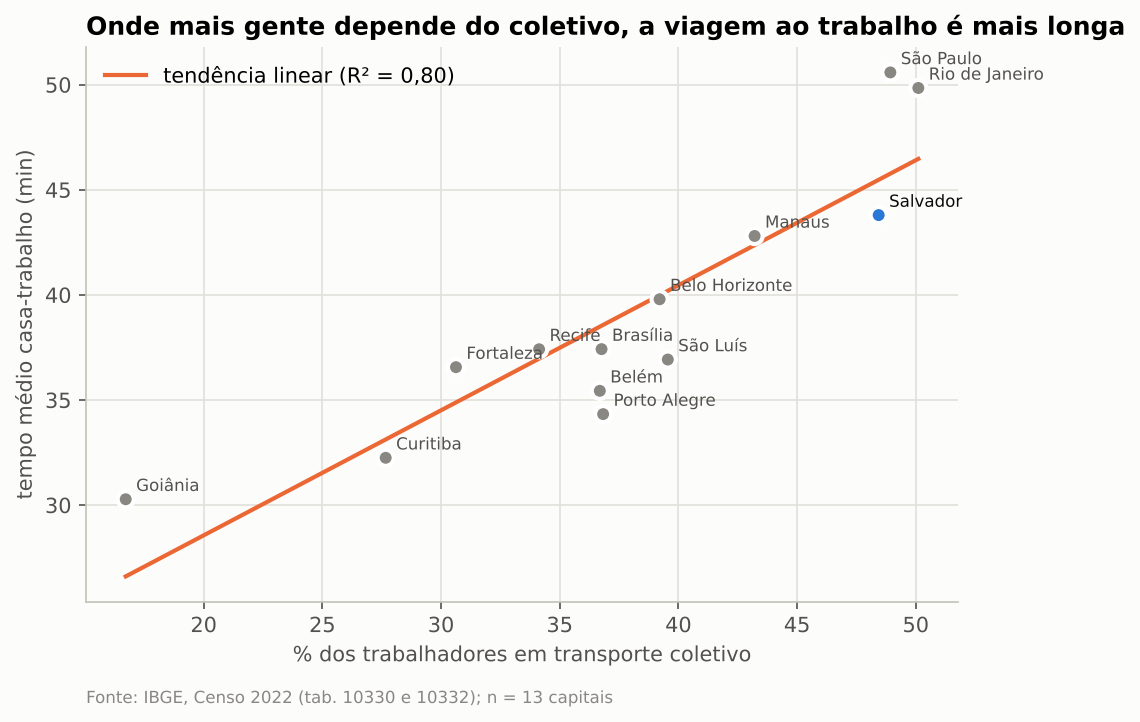

In [20]:
Xr = sm.add_constant(cross[["pct_coletivo", "densidade_2022"]])
ols = sm.OLS(cross["tempo_medio_2022_min"], Xr).fit()
print(ols.summary().tables[1])
print(f"R² = {ols.rsquared:.3f} | R² ajustado = {ols.rsquared_adj:.3f} | n = {int(ols.nobs)}")
R["ols_beta_coletivo"] = float(ols.params["pct_coletivo"])
R["ols_p_coletivo"] = float(ols.pvalues["pct_coletivo"])
R["ols_r2"] = float(ols.rsquared)
R["ols_r2_aj"] = float(ols.rsquared_adj)
pd.DataFrame({"coef": ols.params, "erro_padrao": ols.bse, "t": ols.tvalues, "p_valor": ols.pvalues,
              "ic95_inf": ols.conf_int()[0], "ic95_sup": ols.conf_int()[1]}).to_csv(DADOS / "regressao_ols_tempo.csv")

fig, ax = plt.subplots(figsize=(7.5, 4.8))
x_ = cross["pct_coletivo"]
ax.scatter(x_, cross["tempo_medio_2022_min"], s=60, color=[DESTAQUE if mu == SSA else CINZA for mu in cross["municipio"]],
           edgecolor="white", linewidth=2, zorder=3)
lin = stats.linregress(x_, cross["tempo_medio_2022_min"])
xx = np.linspace(x_.min(), x_.max(), 50)
ax.plot(xx, lin.intercept + lin.slope * xx, color=LARANJA, lw=2, label=f"tendência linear (R² = {lin.rvalue**2:.2f})".replace(".", ","))
for r in cross.itertuples():
    ax.annotate(r.municipio, (r.pct_coletivo, r.tempo_medio_2022_min), xytext=(5, 4), textcoords="offset points", fontsize=8,
                color=TINTA if r.municipio == SSA else TINTA_2)
ax.set_title("Onde mais gente depende do coletivo, a viagem ao trabalho é mais longa")
ax.set_xlabel("% dos trabalhadores em transporte coletivo")
ax.set_ylabel("tempo médio casa-trabalho (min)")
ax.legend(loc="upper left")
fonte(ax, "IBGE, Censo 2022 (tab. 10330 e 10332); n = 13 capitais")
salvar(fig, FIG / "fig14_regressao_tempo_coletivo.png")

**Leitura:** o coletivo em si não é "lento por natureza": o metrô roda em via própria, sem disputar espaço com carros. O que alonga a viagem
é o **ônibus preso no trânsito misto** (16,5 km/h no pico em 2025, segundo a PEMOB). É isso que a seção 7 investiga.

## 7. Diagnóstico das hipóteses sobre a queda de passageiros de ônibus (2019 → 2024)
Pergunta: o STCO caiu de cerca de 1,50 milhão para 1,25 milhão de passageiros por dia (−16,7%, dados da SEMOB).
**Quanto disso cada fator explica?** Fazemos uma **decomposição contábil** (aproximada, baseada em hipóteses
explícitas; não é um experimento, por isso falamos em "fatores associados", não em causa comprovada):

1. **População:** se a taxa de uso por habitante fosse a mesma de 2019, a queda da população reduziria os passageiros
   na mesma proporção.
2. **Metrô:** o ganho de passageiros do metrô por dia no mesmo período, supondo (hipótese **máxima**) que todo esse
   ganho veio de ex-usuários do ônibus.
3. **Restante:** o que sobra está associado a outros fatores: migração para carro/moto (motorização +16% no período),
   aplicativos de transporte, trabalho remoto pós-pandemia e perda de qualidade do serviço (velocidade e confiabilidade).

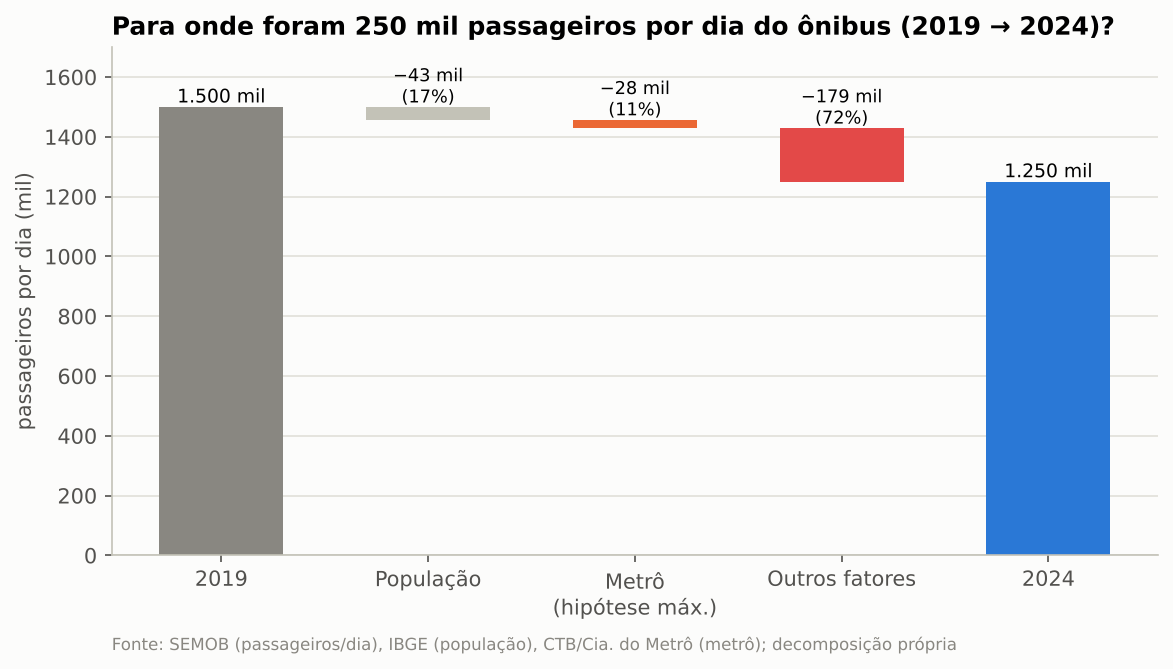

,fator,passageiros_dia,%_da_queda
0,Queda da população,42916.6,17.2
1,Ganho do metrô (hipótese máxima),27676.8,11.1
2,"Outros fatores (carro/moto, apps, remoto, qual...",179406.6,71.8


In [21]:
p19, p24 = base.set_index("ano").loc[2019, "populacao"], base.set_index("ano").loc[2024, "populacao"]
on19, on24 = R["stco_pass_dia_2019"], R["stco_pass_dia_2024"]
queda_total = on19 - on24
ef_pop = on19 * (1 - p24 / p19)
me19, me24 = base.set_index("ano").loc[2019, "metro_passageiros_ano"], base.set_index("ano").loc[2024, "metro_passageiros_ano"]
ef_metro = (me24 - me19) / 365
residual = queda_total - ef_pop - ef_metro
mot19, mot24 = base.set_index("ano").loc[2019, "motorizacao_por_mil_hab"], base.set_index("ano").loc[2024, "motorizacao_por_mil_hab"]
decomp = pd.DataFrame({
    "fator": ["Queda da população", "Ganho do metrô (hipótese máxima)", "Outros fatores (carro/moto, apps, remoto, qualidade)"],
    "passageiros_dia": [ef_pop, ef_metro, residual]})
decomp["%_da_queda"] = decomp["passageiros_dia"] / queda_total * 100
R.update({"queda_total_dia": queda_total, "ef_pop": ef_pop, "ef_metro": ef_metro, "residual": residual,
          "ef_pop_pct": ef_pop / queda_total * 100, "ef_metro_pct": ef_metro / queda_total * 100, "residual_pct": residual / queda_total * 100,
          "var_motoriz_2019_2024_pct": (mot24 / mot19 - 1) * 100})

fig, ax = plt.subplots(figsize=(9, 4.4))
etapas = [("2019", on19, 0, CINZA)]
nivel = on19
for _, r in decomp.iterrows():
    etapas.append((r["fator"], r["passageiros_dia"], nivel - r["passageiros_dia"], [CINZA_CLARO, LARANJA, VERMELHO][len(etapas) - 1]))
    nivel -= r["passageiros_dia"]
etapas.append(("2024", on24, 0, AZUL))
for i, (nome, val, base_y, cor) in enumerate(etapas):
    if nome in ("2019", "2024"):
        ax.bar(i, val / 1e3, color=cor, width=0.6)
        ax.text(i, val / 1e3 + 15, f"{val/1e3:,.0f} mil".replace(",", "."), ha="center", fontsize=9)
    else:
        ax.bar(i, val / 1e3, bottom=base_y / 1e3, color=cor, width=0.6)
        ax.text(i, (base_y + val) / 1e3 + 15, f"−{val/1e3:,.0f} mil\n({val/queda_total*100:.0f}%)".replace(",", "."), ha="center", fontsize=8.5)
rot = ["2019", "População", "Metrô\n(hipótese máx.)", "Outros fatores", "2024"]
ax.set_xticks(range(len(etapas)), rot)
ax.set_ylim(0, 1700)
ax.set_title("Para onde foram 250 mil passageiros por dia do ônibus (2019 → 2024)?")
ax.set_ylabel("passageiros por dia (mil)")
ax.grid(axis="x", visible=False)
fonte(ax, "SEMOB (passageiros/dia), IBGE (população), CTB/Cia. do Metrô (metrô); decomposição própria")
salvar(fig, FIG / "fig15_decomposicao_queda.png")
decomp.round(1)

### 7.1 Quadro de hipóteses

In [22]:
hip = pd.DataFrame([
    ("H1", "O metrô absorveu passageiros do ônibus", "Parcialmente confirmada",
     f"Ganho do metrô explica no máximo {R['ef_metro_pct']:.0f}% da perda do ônibus; parte das viagens de metrô é integrada com ônibus"),
    ("H2", "Carros e motos cresceram e tiraram usuários do coletivo", "Confirmada (associação)",
     f"Motorização +{R['var_motoriz_2019_2024_pct']:.0f}% (2019–2024) e +{R['motorizacao_2025']/R['motorizacao_2014']*100-100:.0f}% desde 2014, com população em queda; motos quase dobraram"),
    ("H3", "A tarifa ficou mais cara acima da inflação", "Fraca / parcialmente",
     f"Tarifa real de R$ {br(R['tarifa_real_2014'], 2)} (2014) para R$ {br(R['tarifa_real_2025'], 2)} (2025): +{(R['tarifa_real_2025']/R['tarifa_real_2014']-1)*100:.0f}% em 11 anos"),
    ("H4", "A pandemia provocou uma quebra estrutural", "Confirmada",
     "Metrô recuperou e bateu recorde em 2024; ônibus seguia cerca de 17% abaixo de 2019 em 2024"),
    ("H5", "A queda da população explica a queda da demanda", "Rejeitada como causa principal",
     f"População caiu cerca de {br((1-p24/p19)*100, 1)}% (2019–2024), explica só {R['ef_pop_pct']:.0f}% da perda de passageiros"),
    ("H6", "O ônibus ficou mais lento (congestionamento)", "Confirmada (2022→2025)",
     f"Velocidade no pico em tráfego misto: {br(R['vel_2022'], 1)} → {br(R['vel_2025'], 1)} km/h ({R['var_vel_pct']:.0f}%); BRT a 22,2 km/h"),
], columns=["id", "hipótese", "resultado", "evidência"])
R["hipoteses"] = hip.to_dict(orient="records")
hip

,id,hipótese,resultado,evidência
0,H1,O metrô absorveu passageiros do ônibus,Parcialmente confirmada,Ganho do metrô explica no máximo 11% da perda ...
1,H2,Carros e motos cresceram e tiraram usuários do...,Confirmada (associação),Motorização +16% (2019–2024) e +46% desde 2014...
2,H3,A tarifa ficou mais cara acima da inflação,Fraca / parcialmente,"Tarifa real de R$ 5,24 (2014) para R$ 5,68 (20..."
3,H4,A pandemia provocou uma quebra estrutural,Confirmada,Metrô recuperou e bateu recorde em 2024; ônibu...
4,H5,A queda da população explica a queda da demanda,Rejeitada como causa principal,"População caiu cerca de 2,9% (2019–2024), expl..."
5,H6,O ônibus ficou mais lento (congestionamento),Confirmada (2022→2025),"Velocidade no pico em tráfego misto: 21,5 → 16..."


### 7.2 Oferta × população (pergunta 1)

In [23]:
pop22, pop25 = base.set_index("ano").loc[2022, "populacao"], base.set_index("ano").loc[2025, "populacao"]
oferta = pd.DataFrame({
    "indicador": ["Ônibus operacionais por 100 mil hab.", "Km rodados por habitante/ano", "Km por ônibus por dia",
                  "Passageiros equivalentes por ônibus/dia", "Velocidade no pico (tráfego misto, km/h)", "Viagens não completadas (%)"],
    "2022": [R["onibus_100mil_2022"], R["km_2022"] / pop22, R["km_2022"] / R["frota_op_2022"] / 365,
             R["pass_equiv_2022"] / R["frota_op_2022"] / 365, R["vel_2022"], R["nao_completadas_2022"]],
    "2025": [R["onibus_100mil_2025"], R["km_2025"] / pop25, R["km_2025"] / R["frota_op_2025"] / 365,
             R["pass_equiv_2025"] / R["frota_op_2025"] / 365, R["vel_2025"], R["nao_completadas_2025"]],
})
oferta["variação_%"] = (oferta["2025"] / oferta["2022"] - 1) * 100
R["km_por_hab_2022"], R["km_por_hab_2025"] = R["km_2022"] / pop22, R["km_2025"] / pop25
R["km_onibus_dia_2022"] = R["km_2022"] / R["frota_op_2022"] / 365
R["km_onibus_dia_2025"] = R["km_2025"] / R["frota_op_2025"] / 365
R["hab_por_linha_2017"] = float(base.set_index("ano").loc[2017, "hab_por_linha"])
R["hab_por_linha_atual"] = pop25 / 515
oferta.round(1)

,indicador,2022,2025,variação_%
0,Ônibus operacionais por 100 mil hab.,74.0,76.5,3.4
1,Km rodados por habitante/ano,47.6,43.9,-7.7
2,Km por ônibus por dia,176.1,157.3,-10.7
3,Passageiros equivalentes por ônibus/dia,275.5,242.5,-12.0
4,"Velocidade no pico (tráfego misto, km/h)",21.5,16.5,-23.3
5,Viagens não completadas (%),5.0,16.2,224.0


**Resposta à pergunta 1:** em **quantidade de ônibus por habitante**, a oferta acompanhou (até superou) a população —
porque a população caiu. Mas a **oferta efetiva** piorou: menos km rodados por habitante, cada ônibus roda menos km
por dia, a velocidade caiu e mais viagens deixam de ser completadas. O problema não é falta de ônibus por habitante:
é **ônibus parado no trânsito**.

**Resposta à pergunta 3 (congestionamento):** cada ônibus transporta cerca de 240 passageiros pagantes-equivalentes por
dia; os mesmos deslocamentos de carro exigiriam centenas de automóveis. O crescimento de **+166 mil autos e +110 mil
motos** (2014–2025) pesa muito mais no trânsito do que a frota de cerca de 1.840 ônibus. Ampliar ônibus **em tráfego misto**
teria efeito limitado (eles ficariam presos no mesmo congestionamento); ampliar **com prioridade viária**
(faixas exclusivas/BRT, onde a velocidade é cerca de 35% maior) aumenta a capacidade sem piorar o trânsito.

In [24]:
R["autos_add_2014_2025"] = int(base.set_index("ano").loc[2025, "autos"] - base.set_index("ano").loc[2014, "autos"])
R["motos_add_2014_2025"] = int(base.set_index("ano").loc[2025, "motos"] - base.set_index("ano").loc[2014, "motos"])
R["pass_por_onibus_dia_2025"] = R["pass_equiv_2025"] / R["frota_op_2025"] / 365
print(R["autos_add_2014_2025"], R["motos_add_2014_2025"], round(R["pass_por_onibus_dia_2025"]))

166156 110486 243


---
# PARTE C. ANÁLISE PREDITIVA: o que deve acontecer até 2030?
Modelos simples e explicáveis, sempre com **cenários** e margem de erro. Projeção não é previsão certa: mostra para
onde a tendência leva **se nada mudar**.

## 8.1 Motorização: regressão linear de tendência (com intervalo de previsão de 95%) e Holt

Validação (treino 2014–2021, teste 2022–2025): MAPE = 0.6%


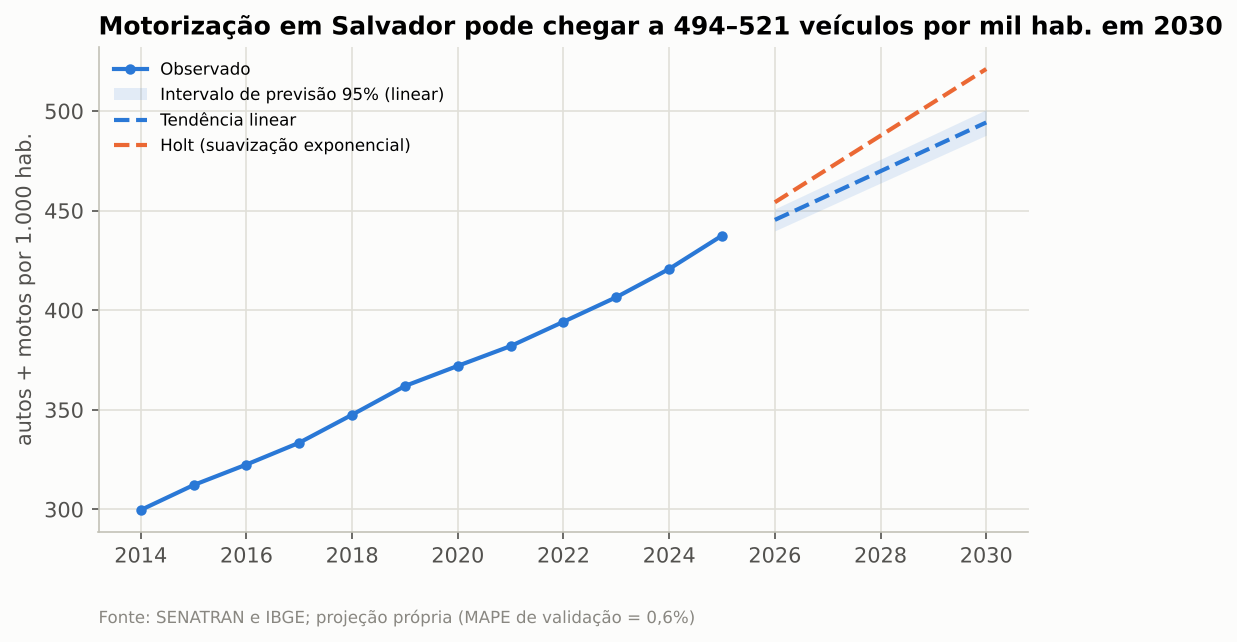

,ano,linear,lim_inf,lim_sup,holt
0,2026,445.3,439.8,450.9,454.2
1,2027,457.6,451.8,463.3,470.9
2,2028,469.8,463.9,475.7,487.6
3,2029,482.0,475.9,488.2,504.4
4,2030,494.3,487.8,500.7,521.1


In [25]:
tr = base[base["ano"] >= 2014][["ano", "motorizacao_por_mil_hab"]].dropna()
mod = sm.OLS(tr["motorizacao_por_mil_hab"], sm.add_constant(tr["ano"])).fit()
fut = pd.DataFrame({"ano": range(2026, 2031)})
pr = mod.get_prediction(sm.add_constant(fut["ano"], has_constant="add")).summary_frame(alpha=0.05)
fut["linear"], fut["lim_inf"], fut["lim_sup"] = pr["mean"].values, pr["obs_ci_lower"].values, pr["obs_ci_upper"].values
holt = ExponentialSmoothing(tr["motorizacao_por_mil_hab"].values, trend="add").fit()
fut["holt"] = holt.forecast(5)
# validação: treina até 2021, testa 2022-2025
tr_tr, tr_te = tr[tr["ano"] <= 2021], tr[tr["ano"] > 2021]
m_val = sm.OLS(tr_tr["motorizacao_por_mil_hab"], sm.add_constant(tr_tr["ano"])).fit()
prev_te = m_val.predict(sm.add_constant(tr_te["ano"], has_constant="add"))
mape_mot = np.mean(np.abs(prev_te.values / tr_te["motorizacao_por_mil_hab"].values - 1)) * 100
print(f"Validação (treino 2014–2021, teste 2022–2025): MAPE = {mape_mot:.1f}%")
R["motoriz_2030_linear"], R["motoriz_2030_holt"] = float(fut["linear"].iloc[-1]), float(fut["holt"].iloc[-1])
R["motoriz_2030_inf"], R["motoriz_2030_sup"] = float(fut["lim_inf"].iloc[-1]), float(fut["lim_sup"].iloc[-1])
R["mape_motoriz"] = mape_mot

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(tr["ano"], tr["motorizacao_por_mil_hab"], color=AZUL, marker="o", ms=4, label="Observado")
ax.fill_between(fut["ano"], fut["lim_inf"], fut["lim_sup"], color=AZUL, alpha=0.12, lw=0, label="Intervalo de previsão 95% (linear)")
ax.plot(fut["ano"], fut["linear"], color=AZUL, ls="--", label="Tendência linear")
ax.plot(fut["ano"], fut["holt"], color=LARANJA, ls="--", label="Holt (suavização exponencial)")
ax.set_title(f"Motorização em Salvador pode chegar a {R['motoriz_2030_linear']:.0f}–{R['motoriz_2030_holt']:.0f} veículos por mil hab. em 2030")
ax.set_ylabel("autos + motos por 1.000 hab.")
ax.legend(loc="upper left", fontsize=8)
fonte(ax, f"SENATRAN e IBGE; projeção própria (MAPE de validação = {mape_mot:.1f}%)".replace(".", ",", 1))
salvar(fig, FIG / "fig16_projecao_motorizacao.png")
fut.round(1)

## 8.2 Metrô: série mensal com Holt-Winters (tendência + sazonalidade)
Treino: jan/2024 a mar/2026 (27 meses); teste: abr a set/2026 (6 meses), para medir o erro (MAPE).

MAPE no teste (6 meses): 1.7% | Previsão 2027: 117.4 milhões de passageiros


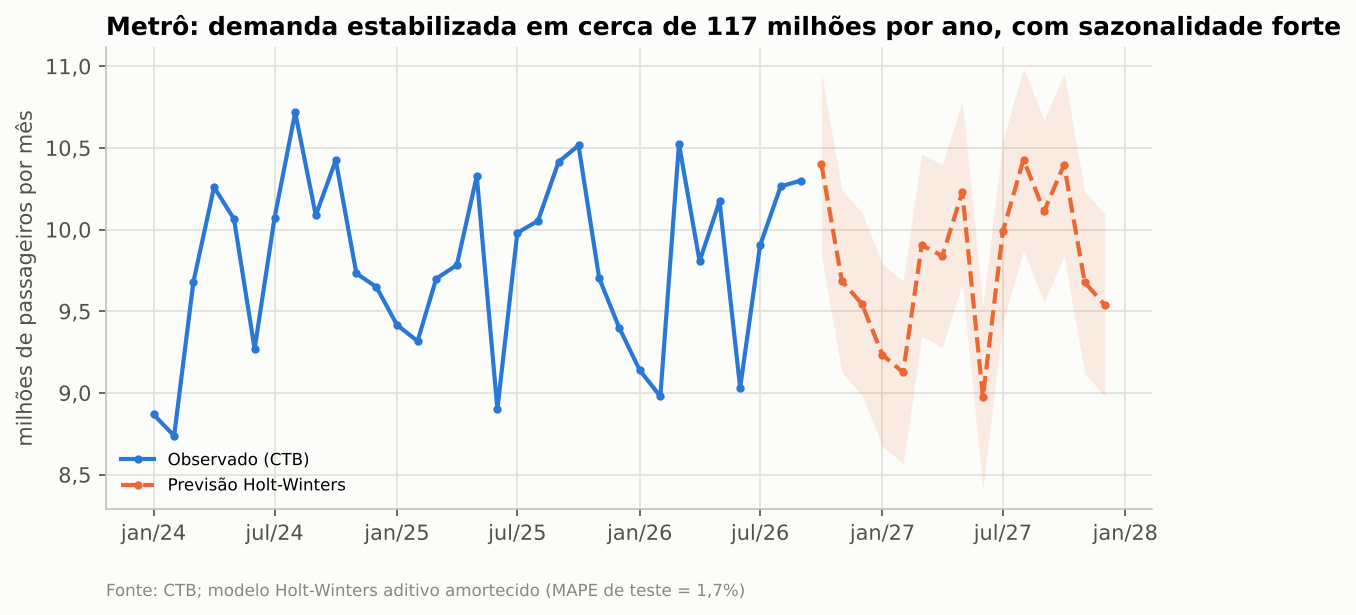

In [26]:
mm = metro_m.copy()
mm["data"] = pd.to_datetime(dict(year=mm["ano"], month=mm["mes"], day=1))
serie = mm.set_index("data")["passageiros"].asfreq("MS")
treino, teste = serie[:-6], serie[-6:]
hw_val = ExponentialSmoothing(treino, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit()
mape_hw = np.mean(np.abs(hw_val.forecast(6).values / teste.values - 1)) * 100
hw = ExponentialSmoothing(serie, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit()
prev = hw.forecast(15)   # out/2026 a dez/2027
resid_sd = np.std(hw.resid)
R["mape_metro_hw"] = mape_hw
R["metro_prev_2027"] = float(prev[prev.index.year == 2027].sum())
print(f"MAPE no teste (6 meses): {mape_hw:.1f}% | Previsão 2027: {R['metro_prev_2027']/1e6:.1f} milhões de passageiros")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(serie.index, serie / 1e6, color=AZUL, marker="o", ms=3, label="Observado (CTB)")
ax.plot(prev.index, prev / 1e6, color=LARANJA, ls="--", marker="o", ms=3, label="Previsão Holt-Winters")
ax.fill_between(prev.index, (prev - 1.96 * resid_sd) / 1e6, (prev + 1.96 * resid_sd) / 1e6, color=LARANJA, alpha=0.12, lw=0)
ax.set_title("Metrô: demanda estabilizada em cerca de 117 milhões por ano, com sazonalidade forte")
eixo_mes(ax, (1, 7))
eixo_br(ax, "y", 1)
ax.set_ylabel("milhões de passageiros por mês")
ax.legend(loc="lower left", fontsize=8)
fonte(ax, f"CTB; modelo Holt-Winters aditivo amortecido (MAPE de teste = {mape_hw:.1f}%)".replace(".", ",", 1))
salvar(fig, FIG / "fig17_previsao_metro.png")

## 8.3 Cenários 2030 para o ônibus e o metrô
| Cenário | Ônibus (passageiros/dia) | Metrô (passageiros/ano) |
|---|---|---|
| **Pessimista** | −5% ao ano (perda acelerada) | 0% (estagnação) |
| **Tendencial** | −3% ao ano (queda histórica informada pela SEMOB) | +1% ao ano |
| **Otimista** | 0% (estabiliza com prioridade viária e integração) | +3% ao ano (expansão Lapa–Campo Grande e integração) |

Hipóteses explícitas (não são metas oficiais). Ponto de partida: 2024 para o ônibus (1,25 milhão/dia, SEMOB) e 2025
para o metrô (117,5 milhões, CTB).

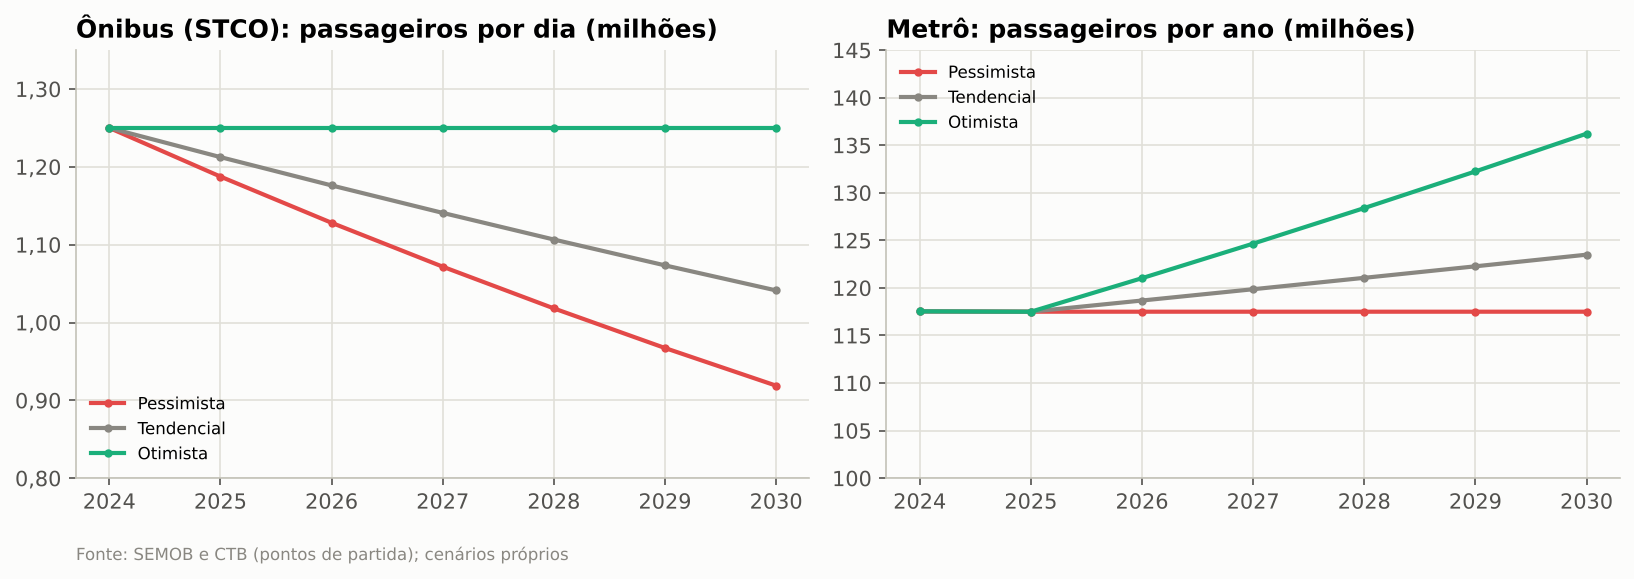

,ano,onibus_pass_dia,metro_pass_ano
cenario,,,
Pessimista,2030,918865.0,117500000.0
Tendencial,2030,1041215.0,123493681.0
Otimista,2030,1250000.0,136214704.0


In [27]:
anos_c = list(range(2024, 2031))
cen = {"Pessimista": (-0.05, 0.00), "Tendencial": (-0.03, 0.01), "Otimista": (0.00, 0.03)}
proj = []
for nome, (g_on, g_me) in cen.items():
    for a in anos_c:
        proj.append({"cenario": nome, "ano": a, "onibus_pass_dia": on24 * (1 + g_on) ** (a - 2024),
                     "metro_pass_ano": me24 if a == 2024 else 117_500_000 * (1 + g_me) ** (a - 2025)})
proj = pd.DataFrame(proj)
pop_2030 = base.set_index("ano").loc[2025, "populacao"] * (2559945 / 2564204) ** 5   # taxa recente do IBGE
R["pop_2030"] = pop_2030
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for (nome, dfc), cor in zip(proj.groupby("cenario", sort=False), [VERMELHO, CINZA, AQUA]):
    axes[0].plot(dfc["ano"], dfc["onibus_pass_dia"] / 1e6, color=cor, marker="o", ms=3, label=nome)
    axes[1].plot(dfc["ano"], dfc["metro_pass_ano"] / 1e6, color=cor, marker="o", ms=3, label=nome)
axes[0].set_title("Ônibus (STCO): passageiros por dia (milhões)")
axes[1].set_title("Metrô: passageiros por ano (milhões)")
axes[0].set_ylim(0.8, 1.35)
eixo_br(axes[0], "y", 2)
axes[1].set_ylim(100, 145)
for ax in axes:
    ax.legend(fontsize=8)
fonte(axes[0], "SEMOB e CTB (pontos de partida); cenários próprios")
fig.tight_layout()
salvar(fig, FIG / "fig18_cenarios_2030.png")
c30 = proj[proj["ano"] == 2030].set_index("cenario")
R["cenarios_2030"] = {k: {"onibus_dia": float(v["onibus_pass_dia"]), "metro_ano": float(v["metro_pass_ano"])} for k, v in c30.iterrows()}
c30.round(0)

---
# PARTE D. ANÁLISE PRESCRITIVA: o que fazer?
## 9. Recomendações para gestores (Prefeitura/SEMOB, Governo do Estado/CTB)
Cada recomendação liga uma **evidência** a uma **ação** e a um **indicador de acompanhamento** (KPI).

In [28]:
recs = pd.DataFrame([
    ("1. Dar prioridade ao ônibus no trânsito", "Velocidade em tráfego misto caiu de 21,5 para 16,5 km/h (2022–2025); BRT roda a 22,2 km/h; quem vai de ônibus leva 59 min contra 32,5 min de carro (Censo 2022)",
     "Ampliar faixas exclusivas/BRS nos corredores mais carregados, com fiscalização eletrônica e semáforos com prioridade", "Velocidade média no pico ≥ 20 km/h até 2028; tempo médio de viagem de ônibus"),
    ("2. Reorganizar a rede em torno do metrô", "Metrô bateu recorde (117,5 mi/ano) e tem demanda estável; ônibus e metrô têm a mesma sazonalidade",
     "Linhas alimentadoras curtas e frequentes até as estações, com integração tarifária e horários coordenados", "% de viagens integradas ônibus–metrô; passageiros/dia nas estações"),
    ("3. Recuperar confiabilidade", "Viagens não completadas subiram de 5% para 16,2% (PEMOB 2022→2025); idade média da frota subiu para 8,4 anos",
     "Contratos com metas de desempenho (cumprimento de viagens, pontualidade) ligadas ao subsídio; renovação de frota já anunciada", "Viagens não completadas < 5%; idade média < 7 anos"),
    ("4. Gerir o crescimento de carros e motos", f"Motorização +46% desde 2014 (motos +92%), com população em queda; projeção de {R['motoriz_2030_linear']:.0f}–{R['motoriz_2030_holt']:.0f} veículos/mil hab. em 2030",
     "Política de estacionamento (rotativo, menos vagas em corredores), segurança viária para motociclistas e campanhas de migração modal", "Motorização por mil hab.; sinistros com motos"),
    ("5. Tarifa e subsídio com foco no usuário", f"Tarifa real subiu {(R['tarifa_real_2025']/R['tarifa_real_2014']-1)*100:.0f}% desde 2014 (R$ {br(R['tarifa_real_2025'], 2)} em 2025, a preços de dez/2025); em 2026 a passagem foi para R$ 5,90",
     "Manter subsídio vinculado a desempenho; estudar tarifa temporal e integração ampliada (ônibus–metrô–ônibus) para baixa renda", "Tarifa real; passageiros equivalentes/ano"),
    ("6. Abrir os dados do transporte", "Não existe série pública do STCO; PEMOB tem lacunas e erros; dados vieram de PDFs e relatórios esparsos",
     "Publicar mensalmente passageiros, frota, km e viagens por linha (dados abertos + GTFS), como faz Belo Horizonte", "Portal de dados abertos ativo; atualização mensal"),
    ("7. Planejar em escala metropolitana", "Salvador perdeu 9,6% da população entre os Censos (2010–2022); quem mora na região metropolitana e trabalha na capital não aparece nos dados municipais",
     "Planejamento conjunto Prefeitura–Estado da rede metropolitana, integrando ônibus metropolitanos, metrô e STCO", "Viagens intermunicipais integradas; tempo de deslocamento > 1h"),
], columns=["recomendação", "evidência", "ação", "indicador (KPI)"])
R["recomendacoes"] = recs.to_dict(orient="records")
recs

,recomendação,evidência,ação,indicador (KPI)
0,1. Dar prioridade ao ônibus no trânsito,"Velocidade em tráfego misto caiu de 21,5 para ...",Ampliar faixas exclusivas/BRS nos corredores m...,Velocidade média no pico ≥ 20 km/h até 2028; t...
1,2. Reorganizar a rede em torno do metrô,"Metrô bateu recorde (117,5 mi/ano) e tem deman...",Linhas alimentadoras curtas e frequentes até a...,% de viagens integradas ônibus–metrô; passagei...
2,3. Recuperar confiabilidade,"Viagens não completadas subiram de 5% para 16,...",Contratos com metas de desempenho (cumprimento...,Viagens não completadas < 5%; idade média < 7 ...
3,4. Gerir o crescimento de carros e motos,"Motorização +46% desde 2014 (motos +92%), com ...","Política de estacionamento (rotativo, menos va...",Motorização por mil hab.; sinistros com motos
4,5. Tarifa e subsídio com foco no usuário,"Tarifa real subiu 8% desde 2014 (R$ 5,68 em 20...",Manter subsídio vinculado a desempenho; estuda...,Tarifa real; passageiros equivalentes/ano
5,6. Abrir os dados do transporte,Não existe série pública do STCO; PEMOB tem la...,"Publicar mensalmente passageiros, frota, km e ...",Portal de dados abertos ativo; atualização mensal
6,7. Planejar em escala metropolitana,"Salvador perdeu 9,6% da população entre os Cen...",Planejamento conjunto Prefeitura–Estado da red...,Viagens intermunicipais integradas; tempo de d...


## 10. Novas perguntas que surgiram (para próximos estudos)
* Qual o papel dos **aplicativos de transporte** (Uber, 99, mototáxi por app)? Não há dado oficial aberto por cidade.
* **Onde** a oferta de ônibus é pior? Exige dados por linha/bairro (GTFS e bilhetagem), hoje não publicados.
* Os moradores que saíram de Salvador foram para onde, e como se deslocam? (Censo 2022: pendularidade intermunicipal.)
* A queda de velocidade 2022→2025 reflete obras (BRT, metrô) ou congestionamento permanente? Exige série mensal de velocidade.
* O crescimento das **motos** está ligado a entregas por aplicativo? Impacto em sinistros de trânsito (DATASUS/RENAEST).

In [29]:
def serializavel(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    return str(o)


with open(DADOS / "resultados_chave.json", "w", encoding="utf-8") as f:
    json.dump(R, f, ensure_ascii=False, indent=2, default=serializavel)
recs.to_csv(DADOS / "recomendacoes.csv", index=False)
hip.to_csv(DADOS / "hipoteses.csv", index=False)
proj.to_csv(DADOS / "cenarios_2030.csv", index=False)
fut.to_csv(DADOS / "projecao_motorizacao.csv", index=False)
oferta.to_csv(DADOS / "oferta_indicadores.csv", index=False)
clu.to_csv(DADOS / "grupos_capitais.csv", index=False)
decomp.to_csv(DADOS / "decomposicao_queda.csv", index=False)
pd.DataFrame({"data": prev.index, "previsao_metro": prev.values}).to_csv(DADOS / "previsao_metro_mensal.csv", index=False)
print(f"{len(list(FIG.glob('*.png')))} figuras salvas em figuras/ e resultados em data/processed/resultados_chave.json")

18 figuras salvas em figuras/ e resultados em data/processed/resultados_chave.json
